# Decision-Focused Volatility Timing (revised version)

Introduction to Financial Engineering, Hanyang University

This notebook evaluates three questions on the US market in 1998-2025:

1. Does volatility timing improve risk or portfolio performance relative to buy and hold?
2. How does variance-forecast accuracy relate to the resulting portfolio performance?
3. Does decision-focused training improve on accuracy training within the same model architecture?

RV and plain GARCH remain the original benchmarks; VIX squared remains an external forecast control. A single completed
training run (`lstm_training_revised.ipynb`) supplies GJR and the GJR-based GARCH-LSTM. Their accuracy-trained forecasts
and exported exposures are reused unchanged across the main comparisons, the Acc/Dec comparison and the exposure plots.

**How to run.** No neural training is performed here. Keep this notebook next to `data/`, put the six completed forecast
CSVs in the folder set by `LSTM_DIR` (`data/LSTM-Forecasts-revised/`), restart the kernel and run all cells (about one
minute with `cache/` present; the first run fits the plain-GARCH forecasts in 5 to 10 minutes). The licensed course CRSP
file is optional and skipped when it is unavailable; it is not redistributed.

The stored outputs come from a full run on the completed revised training files. The original training notebook and the
completed training files are not modified.


**What this revision changes.** GJR and LSTM have one canonical forecast and exposure source. The analysis no longer fits
a second GJR or recalibrates these primary portfolios with a different c history. Model/ensemble QLIKE uses a common
reconstructed RV target; the original stored lagged-RV trading signal is retained. The drawdown plot now includes initial
wealth, like the existing maximum-drawdown statistic.

Costs, caps, risk aversion, evaluation dates, original RV/GARCH/VIX benchmark policies, bootstrap settings, predictive
regressions and exploratory rules are retained. **Calibration and fitting protocols still differ between the unchanged
benchmarks and the completed trained portfolios.** Q2 is therefore a comparison of forecast/strategy procedures, not a
causal experiment where the forecast alone differs. The check in Section 6 shows how much the calibration difference
matters in practice: re-running the GJR and LSTM market forecasts through this notebook's own c rule changes their
Sharpe ratio by at most 0.002.


## 1. Setup and data

All the choices of the backtest are in one place and held fixed for every comparison, except where the ablation
(Section 4 and Appendix D) varies them one at a time. Several of them (the 1998 start, the cap, the rules compared) were settled during
earlier exploratory work on the same data, so the multiple-testing adjustments in Sections 3 and 6 cover the comparisons
reported there, not that exploration.

In [1]:
import hashlib
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq, minimize
from scipy.stats import norm

DATA = Path("data")
CACHE = Path("cache")          # saved GARCH forecasts, so later runs are fast
FIGURES = Path("figures")
CACHE.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

COST = 0.0010          # 10 bp per unit of exposure traded (Moreira and Muir, Table IV)
CAP = 1.5              # exposure stays between 0 and 1.5 (Moreira and Muir, Table V)
MIN_MONTHS = 24        # months of past forecasts needed before we set the first c
FIRST_GARCH_YEAR = 1970
GAMMA = 5              # risk aversion for the certainty equivalent (Section 3c), the same as in the decision objective

PERIODS = {"1998-2025": ("1998-01", "2025-12"),   # main sample
           "1998-2015": ("1998-01", "2015-12"),
           "2016-2025": ("2016-01", "2025-12"),   # last 10 years
           "2021-2025": ("2021-01", "2025-12")}   # last 5 years
MAIN = "1998-2025"

BLOCK, N_BOOT, SEED = 12, 5000, 0   # bootstrap: 12-month blocks, 5000 draws

FACTORS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
N_SEEDS = 5
# Folder containing the six completed factor CSVs; a copied folder or a training run-id folder both work.
LSTM_DIR = DATA / "LSTM-Forecasts-revised"
DFL_FACTORS = {"Mkt": "Mkt-RF", "SMB": "SMB", "HML": "HML", "Mom": "Mom", "RMW": "RMW", "CMA": "CMA"}
DFL_MODELS = {"GJR Acc": "gjr_A", "GJR Dec": "gjr_B",
              "LSTM Acc": "zhao_A_ensemble", "LSTM Dec": "zhao_B_ensemble"}
PRIMARY_EXPORTS = {"GJR": "gjr_A", "LSTM": "zhao_A_ensemble"}

# the forecasts, in the order we show them: the three models, then the two controls
MODELS = ["GARCH", "GJR", "LSTM"]
CONTROLS = ["RV", "VIX2"]
LABEL = {"RV": "RV (last month)", "GARCH": "GARCH(1,1)", "GJR": "GJR-GARCH", "LSTM": "GARCH-LSTM", "VIX2": "VIX²"}
TIMED = {k: f"Timed, {LABEL[k]}" for k in LABEL}

# one colour per portfolio or forecast, used in every chart
COLORS = {"Buy and hold": "black", "RV": "tab:orange", "GARCH": "tab:blue", "GJR": "tab:green", "LSTM": "tab:red",
          "VIX2": "tab:purple", "Vol target (1/σ)": "tab:olive", "Xu switches": "tab:brown", "Conditional": "tab:pink",
          "EW factors": "goldenrod", "EW CRSP stocks": "tab:cyan"}
for k in LABEL:
    COLORS[TIMED[k]] = COLORS[k]
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "axes.axisbelow": True})


def as_time(index):
    # month strings ("1998-01") to timestamps for plotting
    return pd.PeriodIndex(index, freq="M").to_timestamp()

# the six crisis episodes used in Section 3 and the appendices (first and last month)
CRISES = {"Dot-com\n2000-02": ("2000-09", "2002-09"), "Financial\n2007-09": ("2007-11", "2009-02"),
          "Euro\n2011": ("2011-05", "2011-09"), "Q4 2018": ("2018-10", "2018-12"),
          "Covid\n2020": ("2020-02", "2020-03"), "Bear\n2022": ("2022-01", "2022-09")}


**Data.**

Market, factor and risk-free data come from the Kenneth French data library (daily and monthly, from July 1963), the VIX
from FRED (CBOE VIX, series VIXCLS), and the stock-level data from the course CRSP extract (2000-2020). The factors are
long-short portfolios, so they are already excess returns. Each month's realised variance is the sum of its squared daily
returns, without subtracting the month's mean (Andersen and Bollerslev, 1998); Moreira and Muir (2017, eq. 2) subtract it,
and a demeaned-RV sensitivity diagnostic remains in Section 3.

**Data vintage.** The Ken French files are rebuilt from the current CRSP database (here the August 2026 version), so past
returns are today's revised values, not the numbers an investor saw at the time. Every decision uses only observations
dated before it, taken from revised history, and we assume the previous month's returns were observable at each rebalance.

**Market.** The CRSP value-weighted index of all US stocks (Ken French's Mkt-RF), which moves almost one for one with the
S&P 500, so "buy and hold" is effectively holding the index.

**Two more passive benchmarks** for Appendix B:
- **EW factors:** an equal-weighted portfolio of the six factors (Mkt-RF, SMB, HML, RMW, CMA, Mom), rebalanced monthly.
- **EW CRSP stocks:** an equal-weighted portfolio of the course's CRSP stocks, 2000-2020. `ADJ_PRC` is adjusted for
  splits and dividends (the Microsoft check below), so price changes are total returns. The portfolio holds every stock
  with a price at the end of the previous month (6,972 in February 2000, 4,268 at the end). Stock-months with no price at
  the end of the month (delisted, or a gap in the file; there are no delisting returns) are dropped and their weight
  spread over the rest, so it is an available-return illustration. The cost of rebalancing thousands of stocks is ignored.


In [2]:
monthly = pd.read_csv(DATA / "ff_monthly_baselinedata.csv")
daily = pd.read_csv(DATA / "ff_daily_garchdata_long.csv")
daily["date"] = pd.to_datetime(daily["Date"], format="%d-%m-%Y")
rf = pd.read_csv(DATA / "ff_monthly_rf.csv", index_col="month")["RF"]

ret = monthly.pivot(index="month", columns="series", values="ret_m").loc["1963-07":"2025-12", FACTORS]
rv = monthly.pivot(index="month", columns="series", values="rv").loc["1963-07":"2025-12", FACTORS]   # realised variance
daily_ret = daily.pivot(index="date", columns="series", values="ret").sort_index()
mkt = ret["Mkt-RF"]
ew_factors = ret[FACTORS].mean(axis=1)            # equal-weighted six factors, rebalanced monthly (an excess return)

# VIX squared at each month end, turned into a monthly variance
vix = pd.read_csv(DATA / "VIXCLS.csv")
vix.columns = ["date", "vix"]
vix["date"] = pd.to_datetime(vix["date"])
vix["vix"] = pd.to_numeric(vix["vix"], errors="coerce")
vix = vix.dropna().set_index("date")["vix"].resample("ME").last()
vix.index = vix.index.strftime("%Y-%m")
vix_var = vix ** 2 / 12 / 1e4

# One canonical forecast source for GJR and GJR-based LSTM, for all sections.
def load_trained_forecasts(folder, returns, risk_free, variance):
    expected = pd.period_range("1975-01", "2025-12", freq="M").astype(str)
    models = tuple(DFL_MODELS.values())
    seeds = [f"V_zhao_{obj}_s{i}" for obj in ("A", "B") for i in range(N_SEEDS)]
    required = ["f", "rf", "rv", *seeds,
                *(f"{prefix}_{model}" for model in models for prefix in ("V", "C", "W"))]
    files = {}
    for factor, series in DFL_FACTORS.items():
        path = folder / f"{factor}_forecasts.csv"
        g = pd.read_csv(path, index_col="month").loc[:"2025-12"]
        if not g.index.equals(expected):
            raise ValueError(f"{path}: expected consecutive unique months 1975-01 through 2025-12")
        missing = set(required) - set(g.columns)
        if missing:
            raise ValueError(f"{path}: missing columns {sorted(missing)}")
        values = g[required].to_numpy(float)
        if not np.isfinite(values).all():
            raise ValueError(f"{path}: nonfinite inputs")
        for obj in ("A", "B"):
            columns = [c for c in g if c.startswith(f"V_zhao_{obj}_s")]
            if len(columns) != N_SEEDS:
                raise ValueError(f"{path}: expected {N_SEEDS} seeds for {obj}")
            np.testing.assert_allclose(g[f"V_zhao_{obj}_ensemble"], g[columns].mean(axis=1),
                                       rtol=1e-8, atol=1e-12, err_msg=f"{path}: ensemble mismatch")
        np.testing.assert_allclose(g["f"], returns[series].reindex(g.index), rtol=1e-8, atol=1e-12)
        np.testing.assert_allclose(g["rf"], risk_free.reindex(g.index), rtol=1e-8, atol=1e-12)
        np.testing.assert_allclose(g["rv"], variance[series].reindex(g.index), rtol=1e-8, atol=1e-12)
        if (g["rv"] <= 0).any():
            raise ValueError(f"{path}: realized variance must be positive")
        for model in models:
            V, c, w = (g[f"{prefix}_{model}"] for prefix in ("V", "C", "W"))
            if (V <= 0).any() or (c <= 0).any() or ((w < 0) | (w > CAP + 1e-10)).any():
                raise ValueError(f"{path}: invalid forecasts, scales or exposures for {model}")
            np.testing.assert_allclose(w, (c / V).clip(0, CAP), rtol=1e-8, atol=1e-10,
                                       err_msg=f"{path}: weight does not match exported c and forecast")
            if (c.groupby(g.index.str[:4]).nunique() != 1).any():
                raise ValueError(f"{path}: c must be constant within each forecast year")
        files[factor] = g
    return files


# Use the training run's exact RV convention for accuracy; retain stored lagged RV for the original RV strategy.
rv_eval = daily_ret[FACTORS].pow(2).groupby(daily_ret.index.to_period("M")).sum(min_count=1)
rv_eval.index = rv_eval.index.astype(str)
rv_eval = rv_eval.reindex(ret.index)
lstm_files = load_trained_forecasts(LSTM_DIR, ret, rf, rv_eval)

# the course CRSP stocks (licensed file: skipped if missing)
# looked for in data/ (gzip-compressed or plain), next to this notebook, and one folder up
CRSP_FILE = next((f for f in [DATA / "IFE_term_stock_data.csv.gz", DATA / "IFE_term_stock_data.csv", Path("IFE_term_stock_data.csv"),
                              Path("..") / "IFE_term_stock_data.csv"] if f.exists()), None)
crsp_ex = None
if CRSP_FILE is None:
    print("The course CRSP file is licensed and not distributed. Put IFE_term_stock_data.csv in data/ to add the CRSP benchmark.")
else:
    crsp = pd.read_csv(CRSP_FILE, usecols=["PERMNO", "date", "TICKER", "ADJ_PRC"])
    crsp["month"] = crsp["date"].str[:7]
    # dividends in ADJ_PRC? Microsoft paid $3.08 a share in November 2004; its price fell 4.2% but the total return was +6.9%
    msft = crsp[crsp["TICKER"] == "MSFT"].set_index("month")["ADJ_PRC"]
    print(f"Microsoft, November 2004, return from ADJ_PRC: {msft['2004-11'] / msft['2004-10'] - 1:+.1%}")
    prices = crsp.pivot_table(index="month", columns="PERMNO", values="ADJ_PRC")
    held = prices.shift(1).notna()                    # every stock with a price at the end of last month
    stock_ret = prices / prices.shift(1) - 1
    crsp_ex = (stock_ret.where(held).mean(axis=1) - rf).dropna()     # equal-weighted excess return, available returns
    print(f"CRSP: {int(held.sum(axis=1).iloc[1])} stocks in the first month, {int(held.sum(axis=1).iloc[-1])} in the last, "
          f"{crsp_ex.index[0]} to {crsp_ex.index[-1]}")

print(f"{len(ret)} months, {ret.index[0]} to {ret.index[-1]}")
summary = pd.DataFrame({"mean %/yr": 1200 * ret.mean(), "vol %/yr": 100 * ret.std() * 12 ** 0.5,
                        "Sharpe": ret.mean() / ret.std() * 12 ** 0.5})
summary.loc["EW factors"] = [1200 * ew_factors.mean(), 100 * ew_factors.std() * 12 ** 0.5,
                             ew_factors.mean() / ew_factors.std() * 12 ** 0.5]
summary


Microsoft, November 2004, return from ADJ_PRC: +6.9%


CRSP: 6972 stocks in the first month, 4268 in the last, 2000-02 to 2020-12
750 months, 1963-07 to 2025-12


,mean %/yr,vol %/yr,Sharpe
series,,,
Mkt-RF,7.132,15.447,0.462
SMB,2.163,10.488,0.206
HML,3.431,10.293,0.333
RMW,3.191,7.693,0.415
CMA,2.870,7.147,0.402
Mom,7.144,14.471,0.494
EW factors,4.322,4.010,1.078


## 2. Forecasts and portfolio construction

Each procedure forecasts monthly variance, chooses an exposure, and holds it for a month. The inverse-variance formula,
cap and cost convention are common. Plain GARCH/RV/VIX retain the original analysis calibration; GJR/LSTM use the annual
calibration and exposures saved by completed training. This distinction is explicit rather than silently recalibrating
the trained portfolios. The separate 1/sigma benchmark and retrospective scale diagnostics remain in the appendices.


The primary forecasts are:

| Forecast | Source |
|---|---|
| RV | Previous month's stored realized variance, unchanged benchmark |
| GARCH(1,1) | Original plain-GARCH estimator and cached forecasts in this notebook |
| GJR Acc | `V_gjr_A` from completed revised training |
| GJR-based GARCH-LSTM Acc | `V_zhao_A_ensemble`, averaging five variance forecasts before allocation |
| VIX squared | Previous month-end VIX converted to monthly variance, unchanged control |

GJR and LSTM are not refitted here. The revised training uses common core factor definitions from 1963, a zero mean,
fresh annual initialization, a five-year validation block and retained selected checkpoints. It exports each later
year's forecasts and exposures. Parameters are fitted before validation; they are not automatically refitted on the
validation years. Plain GARCH keeps its earlier all-pre-year fitting procedure.

The monthly horizon remains 21 trading days. The LSTM's next-day forecast is extended with the declared GJR
mean-reversion approximation, not a full neural forward simulation.


In [3]:
def softplus(z):
    return np.log1p(np.exp(z))


def garch_params(raw):
    w = np.exp(np.r_[raw[1:3], 0.0])
    w = w / w.sum()
    return softplus(raw[0]) * 0.1, w[0], w[1]


def garch_path(raw, r, h0):
    omega, alpha, beta = garch_params(raw)
    T = len(r)
    x = omega + alpha * r[:-1] ** 2
    j = np.arange(T - 1)
    n = 2 * T
    conv = np.fft.irfft(np.fft.rfft(x, n) * np.fft.rfft(beta ** j, n), n)[:T - 1]
    return np.r_[h0, conv + h0 * beta ** (j + 1)]


def garch_loss(raw, r):
    h = garch_path(raw, r, r.var())
    return 0.5 * np.mean(np.log(h[1:]) + r[1:] ** 2 / h[1:])


def garch_monthly(name, r):
    """Original annual plain-GARCH benchmark; GJR forecasts are loaded from completed training."""
    # Keep the original False flag in the fingerprint so existing plain-GARCH caches remain usable.
    key = hashlib.md5(pd.util.hash_pandas_object(r).to_numpy().tobytes() + f"False{FIRST_GARCH_YEAR}".encode()).hexdigest()[:8]
    file = CACHE / f"garch_{name}_{key}.csv"
    if file.exists():
        v = pd.read_csv(file, index_col="month")["v_hat"]
        assert v.index.is_unique and v.notna().all() and (v > 0).all(), f"damaged cache file {file}, delete it"
        return v
    r = r.dropna().sort_index() * 100
    first_day = r.groupby(r.index.to_period("M")).apply(lambda z: z.index[0])
    raw = np.array([-1.0, -2.0, 1.5])
    out = {}
    for year in range(FIRST_GARCH_YEAR, 2026):
        train = r.loc[:f"{year - 1}-12-31"].to_numpy()
        fit = minimize(garch_loss, raw, args=(train,), method="L-BFGS-B")
        if not fit.success:
            print(f"warning: {name} {year} fit did not converge ({fit.message})")
        raw = fit.x
        omega, alpha, beta = garch_params(raw)
        phi = alpha + beta
        h = pd.Series(garch_path(raw, r.loc[:f"{year}-12-31"].to_numpy(), train.var()),
                      index=r.loc[:f"{year}-12-31"].index)
        for month, day0 in first_day.items():
            if month.year != year:
                continue
            h1 = h.loc[day0]
            if phi > 1 - 1e-10:
                out[str(month)] = 21 * h1 / 1e4
            else:
                vbar = omega / (1 - phi)
                out[str(month)] = sum(vbar + phi ** (k - 1) * (h1 - vbar) for k in range(1, 22)) / 1e4
    v = pd.Series(out, name="v_hat")
    v.index.name = "month"
    v.to_csv(file)
    return v


def qlike(v_hat, v_true):
    x = v_true / v_hat
    return float(np.mean(x - np.log(x) - 1))


r_mkt = daily_ret["Mkt-RF"]
lstm_mkt = lstm_files["Mkt"]
forecasts = pd.DataFrame({
    "GARCH": garch_monthly("Mkt-RF", r_mkt).reindex(ret.index),
    "GJR": lstm_mkt["V_gjr_A"].reindex(ret.index),
    "LSTM": lstm_mkt["V_zhao_A_ensemble"].reindex(ret.index),
    "RV": rv["Mkt-RF"].shift(1),
    "VIX2": vix_var.shift(1).reindex(ret.index),
})
FORECASTS = MODELS + CONTROLS

a, b = PERIODS[MAIN]
assert forecasts.loc[a:b].notna().all().all() and (forecasts.loc[a:b] > 0).all().all()
accuracy = pd.Series({k: qlike(forecasts[k].loc[a:b], rv_eval["Mkt-RF"].loc[a:b]) for k in FORECASTS}, name="QLIKE 1998-2025")
accuracy.rename(index=LABEL).to_frame()


,QLIKE 1998-2025
"GARCH(1,1)",0.297
GJR-GARCH,0.284
GARCH-LSTM,0.280
RV (last month),0.454
VIX²,0.275


**Each forecast against the volatility that followed.** Annualised volatility (square root of 12 times the monthly
variance), log scale, 1998-2025. The grey line is the realised volatility of the month being forecast; the coloured line
is the forecast made at the end of the month before. The last panel zooms in on 2008-2009 and 2020, where the forecasts
differ most.

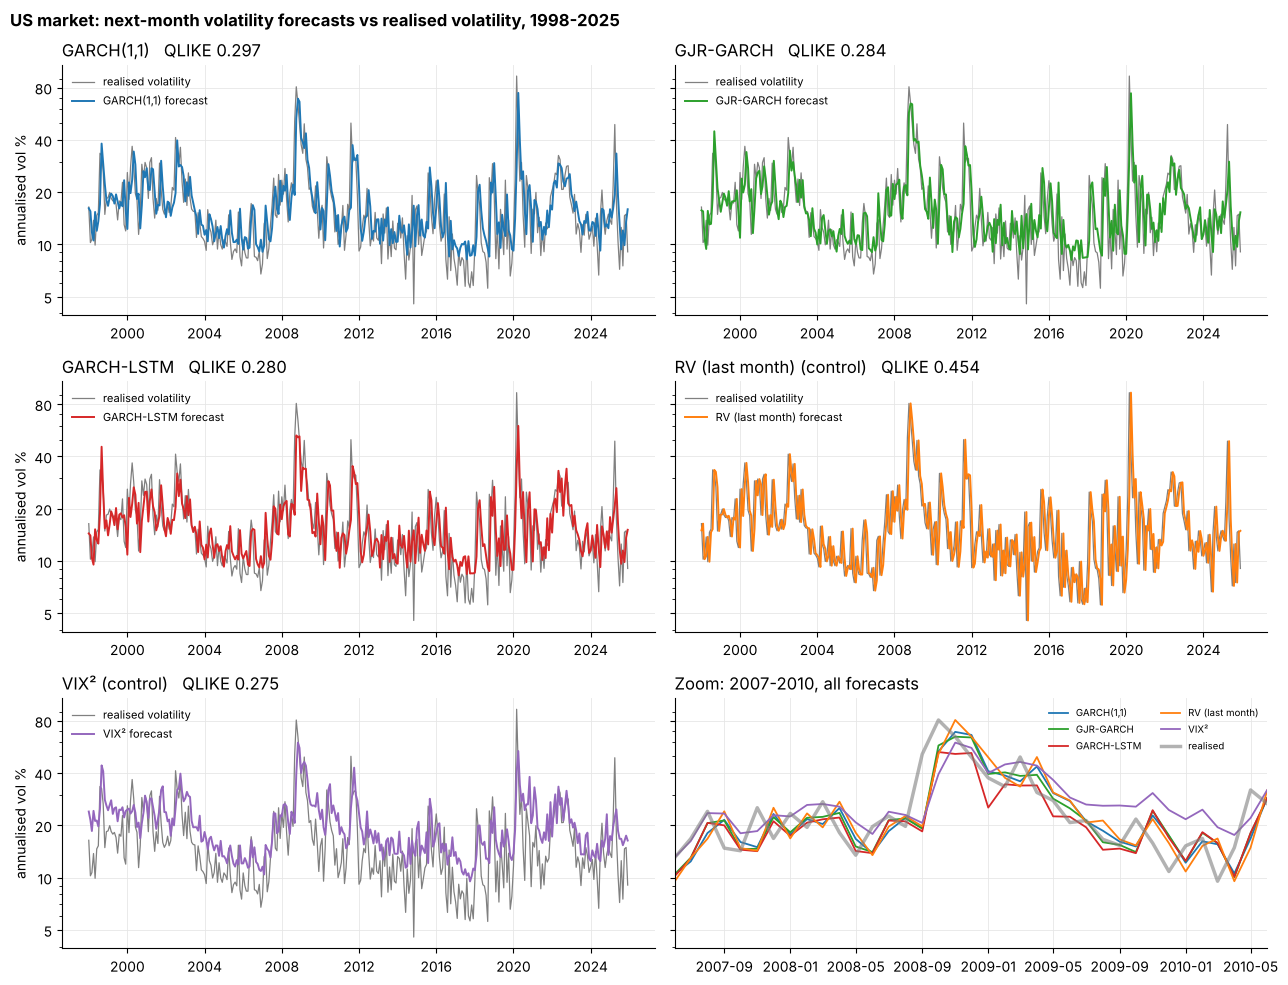

In [4]:
a, b = PERIODS[MAIN]
vol = lambda v: 100 * np.sqrt(12 * v)
t = as_time(ret.loc[a:b].index)
real = vol(rv_eval["Mkt-RF"].loc[a:b])
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharey=True)
for ax, k in zip(axes.ravel(), FORECASTS):
    ax.plot(t, real, color="grey", lw=0.9, label="realised volatility")
    ax.plot(t, vol(forecasts[k].loc[a:b]), color=COLORS[k], lw=1.4, label=f"{LABEL[k]} forecast")
    ax.set_title(f"{LABEL[k]}{' (control)' if k in CONTROLS else ''}   QLIKE {accuracy[k]:.3f}", loc="left")
    ax.legend(loc="upper left", frameon=False, fontsize=8)
ax = axes.ravel()[-1]
for k in FORECASTS:
    ax.plot(t, vol(forecasts[k].loc[a:b]), color=COLORS[k], lw=1.3, label=LABEL[k])
ax.plot(t, real, color="grey", lw=2.5, alpha=0.6, label="realised")
ax.set_xlim(pd.Timestamp("2007-06-01"), pd.Timestamp("2010-06-01"))
ax.set_title("Zoom: 2007-2010, all forecasts", loc="left")
ax.legend(loc="upper right", frameon=False, fontsize=7, ncol=2)
for ax in axes.ravel():
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(plt.ScalarFormatter())
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks([5, 10, 20, 40, 80])
axes[0, 0].set_ylabel("annualised vol %")
axes[1, 0].set_ylabel("annualised vol %")
axes[2, 0].set_ylabel("annualised vol %")
plt.suptitle("US market: next-month volatility forecasts vs realised volatility, 1998-2025", x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "fig02_forecasts_vs_realised.png", dpi=150)
plt.show()


**Reading the forecasts.** QLIKE measures error against monthly realised variance (lower is better). Over 1998-2025 VIX²
is the most accurate (0.275), then the GARCH-LSTM (0.280), GJR-GARCH (0.284), GARCH(1,1) (0.297) and last month's RV
(0.454). The two trained models are almost equally accurate; the neural part improves on its GJR base by only 0.004.
VIX² owes its lead to 2016-2025, while GJR and the GARCH-LSTM are best in 1998-2015 (Appendix E1). Forecast accuracy and
the allocation's return/risk profile answer different questions; Section 4 compares them.


**2b. The timing rule**

$$w_t=\min(c_t/\widehat V_t,1.5).$$

Higher expected variance reduces exposure. The scale c has variance units; sqrt(12c) is the annualized forecast-volatility
threshold for unit exposure, not a guaranteed portfolio volatility target.

For RV, plain GARCH and VIX, c retains the original annual calibration on earlier stored forecast/return pairs. For
GJR/LSTM, use exported C and W columns: each newly fitted model re-filters pre-year history to calibrate c, then holds c
fixed through the forward year. Both use past information, but their calibration histories differ. Historical model-path
replay inside training is in sample for its parameters; only the later exported year is a forward test.

The cap applies at rebalance. Cash earns RF, borrowing is at RF with zero spread, and costs are 10 bp per unit traded
from the drifted position. The existing drift approximation and free initial entry are retained. Compute full-path
returns before slicing evaluation periods. The industry-style 1/sigma benchmark is a separate procedure.


In [5]:
def c_vol_match(v, f, cap=CAP):
    # c such that the capped timed series has the same volatility as the asset itself
    v, f = np.asarray(v, float), np.asarray(f, float)
    target = f.std(ddof=1)
    if cap is None:
        return target / (f / v).std(ddof=1)
    gap = lambda c: (np.clip(c / v, 0, cap) * f).std(ddof=1) - target
    hi = target / (f / v).std(ddof=1)
    while gap(hi) < 0:
        hi *= 2
    return brentq(gap, 1e-12, hi, xtol=1e-16)


def c_path(v, f, cap=CAP, frozen_window=None):
    """The c used in each month: reset every January on past months only, or set once on a fixed window."""
    v, f = v.astype(float), f.reindex(v.index).astype(float)
    ok = v.notna() & f.notna()
    if frozen_window:   # the same volatility match, done once on a fixed window and never updated
        win = (v.index >= frozen_window[0]) & (v.index <= frozen_window[1]) & ok
        return pd.Series(c_vol_match(v[win], f[win], cap), index=v.index)
    c = pd.Series(np.nan, index=v.index)
    for year in sorted({m[:4] for m in v.index[v.notna()]}):
        past = ok & (v.index < f"{year}-01")
        if past.sum() >= MIN_MONTHS:
            c[v.index.str[:4] == year] = c_vol_match(v[past], f[past], cap)
    return c


def timing_weights(v, f, cap=CAP, frozen_window=None):
    """Exposure c / v, capped. c is reset every January on past months only (or frozen once, for the ablation)."""
    return (c_path(v, f, cap, frozen_window) / v).clip(0, np.inf if cap is None else cap)


def drifted(w, ex, r_f):
    # where each month's position has drifted to by the end of the month, before we rebalance
    return np.r_[w[0], w[:-1] * (1 + ex[:-1] + r_f[:-1]) / (1 + r_f[:-1] + w[:-1] * ex[:-1])]


def backtest(w, ex, cost=COST):
    """Monthly net excess return of holding w in an asset with excess return ex."""
    w = w.dropna()
    ex, r_f, wv = ex.reindex(w.index).to_numpy(), rf.reindex(w.index).to_numpy(), w.to_numpy()
    return pd.Series(wv * ex - cost * np.abs(wv - drifted(wv, ex, r_f)), index=w.index)


def turnover(w, ex):
    """Exposure traded each month (the amount we pay costs on)."""
    w = w.dropna()
    ex, r_f, wv = ex.reindex(w.index).to_numpy(), rf.reindex(w.index).to_numpy(), w.to_numpy()
    return pd.Series(np.abs(wv - drifted(wv, ex, r_f)), index=w.index)


# Forecast volatility associated with unit exposure; this is not a guaranteed portfolio volatility target.
a, b = PERIODS[MAIN]
scales = {k: (lstm_mkt[f"C_{PRIMARY_EXPORTS[k]}"].reindex(ret.index) if k in PRIMARY_EXPORTS
              else c_path(forecasts[k], mkt)) for k in FORECASTS}
targets = pd.DataFrame({LABEL[k]: 100 * np.sqrt(12 * scales[k]) for k in FORECASTS}).loc[a:b]
jan = targets[targets.index.str.endswith("-01")]
jan.index = jan.index.str[:4]
print("Forecast volatility for unit exposure sqrt(12 c), % a year (every 5th January shown):")
jan.iloc[::5]


Forecast volatility for unit exposure sqrt(12 c), % a year (every 5th January shown):


,"GARCH(1,1)",GJR-GARCH,GARCH-LSTM,RV (last month),VIX²
month,,,,,
1998,12.136,12.193,12.237,11.404,17.524
2003,12.997,12.938,13.198,12.327,21.752
2008,12.989,13.142,13.192,12.317,21.060
2013,13.795,13.776,13.945,13.146,22.788
2018,13.762,13.896,13.926,13.105,21.978
2023,14.293,14.276,14.423,13.627,22.104


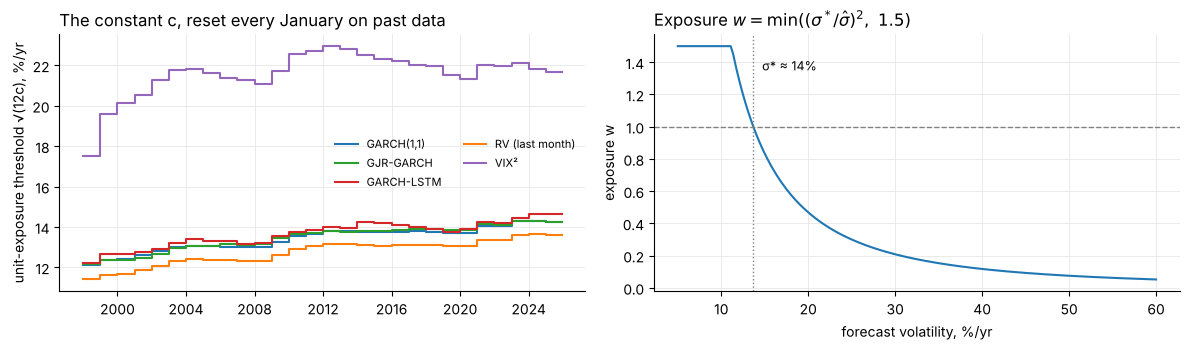

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k in FORECASTS:
    ax[0].step(as_time(targets.index), targets[LABEL[k]], where="post", color=COLORS[k], label=LABEL[k])
ax[0].set_ylabel("unit-exposure threshold √(12c), %/yr")
ax[0].set_title("The constant c, reset every January on past data", loc="left")
ax[0].legend(frameon=False, fontsize=8, ncol=2)
# how the rule turns a forecast into an exposure, for the GARCH(1,1) target of a typical year
s = targets[LABEL["GARCH"]].median()
fv = np.linspace(5, 60, 200)
ax[1].plot(fv, np.minimum((s / fv) ** 2, CAP), color=COLORS["GARCH"])
ax[1].axhline(1, color="grey", ls="--", lw=1)
ax[1].axvline(s, color="grey", ls=":", lw=1)
ax[1].text(s + 1, 1.35, f"σ* ≈ {s:.0f}%", fontsize=9)
ax[1].set_xlabel("forecast volatility, %/yr")
ax[1].set_ylabel("exposure w")
ax[1].set_title(r"Exposure $w = \min((\sigma^*/\hat\sigma)^2,\ 1.5)$", loc="left")
plt.tight_layout()
plt.savefig(FIGURES / "fig02_timing_rule.png", dpi=150)
plt.show()


The table reports sqrt(12c), the forecast-volatility threshold at which uncapped exposure equals one. GJR and LSTM use
their saved C columns; benchmarks use the original c path. Differences in these thresholds can reflect forecast scale
and calibration history. They should not be read as realized or guaranteed portfolio volatility.


## 3. Q1: Does volatility timing improve on buy and hold?

Compare buy and hold with the original RV/GARCH timing benchmarks and the completed GJR Acc/LSTM Acc portfolios.
The same trained exposures are used again in Q3. VIX remains a control in the broader comparison.

The scorecard reports monthly net-excess-return Sharpe and Sortino, annualized arithmetic mean excess return,
month-end total-wealth drawdown, exposure, borrowing and turnover. Arithmetic annualized return is not CAGR.


In [7]:
def sharpe(z):
    z = np.asarray(z, float)
    return z.mean() / z.std(ddof=1) * np.sqrt(12) if z.std(ddof=1) > 0 else 0.0


def sortino(z):
    z = np.asarray(z, float)
    down = np.sqrt(np.mean(np.minimum(z, 0) ** 2))
    return z.mean() * 12 / (down * np.sqrt(12))


def max_drawdown(z, r_f):
    # largest fall of month-end total-return wealth from its previous month-end peak
    wealth = np.r_[1.0, np.cumprod(1 + np.asarray(z) + np.asarray(r_f))]
    return (wealth / np.maximum.accumulate(wealth) - 1).min()


def drawdown_path(z, r_f):
    wealth = (1 + z + r_f.reindex(z.index)).cumprod()
    peak = np.maximum.accumulate(np.r_[1.0, wealth.to_numpy()])[1:]
    return 100 * (wealth / peak - 1)


def mt_vt(w, R):
    # gross Sharpe(timed) / Sharpe(buy and hold) = MT x VT, before costs, with exposure scaled to mean 1 (Section 4)
    x = w / w.mean()
    mt, vt = (x * R).mean() / R.mean(), R.std() / (x * R).std()
    assert np.isclose(mt * vt, sharpe(w * R) / sharpe(R))   # the identity holds exactly
    return mt, vt


def same_vol_as(z, target):
    # ex-post diagnostic: scale z to the volatility of target over the whole sample (the Sharpe ratio does not change)
    return z * target.std() / z.std()


def vol_of_vol(z):
    # how much the portfolio's own risk moves around: sd of its 12-month rolling volatility (annualised, %)
    return 100 * (pd.Series(np.asarray(z, float)).rolling(12).std() * 12 ** 0.5).std()


def cer(z, gamma=GAMMA):
    # certainty-equivalent excess return of a mean-variance investor, % a year
    z = np.asarray(z, float)
    return 1200 * (z.mean() - gamma / 2 * z.var(ddof=1))


# statistical tests used in Sections 3 and 6 (described in Section 3c)
def boot_index(n):
    # N_BOOT resamples of n months, built from 12-month blocks that start anywhere and wrap around the end (circular)
    rng = np.random.default_rng(SEED)
    starts = rng.integers(0, n, (N_BOOT, int(np.ceil(n / BLOCK))))
    return ((starts[:, :, None] + np.arange(BLOCK)) % n).reshape(N_BOOT, -1)[:, :n]


def paired(*series):
    # the tests compare month by month, so every series must cover exactly the same months, with no gaps
    assert all(s.index.equals(series[0].index) for s in series), "series cover different months"
    X = np.column_stack([np.asarray(s, float) for s in series])
    assert np.isfinite(X).all(), "missing values"
    return X


def bootstrap(X, stat):
    """Paired circular block bootstrap of stat(X): estimate, symmetric 95% interval and two-sided p-value for stat = 0."""
    est = stat(X)
    err = np.abs(np.array([stat(X[i]) for i in boot_index(len(X))]) - est)
    half = np.percentile(err, 95)
    p = (1 + np.sum(err >= abs(est))) / (len(err) + 1)
    return est, est - half, est + half, p


def bootstrap_test(x, y):
    """Sharpe(x) - Sharpe(y) with the paired block bootstrap."""
    return bootstrap(paired(x, y), lambda X: sharpe(X[:, 0]) - sharpe(X[:, 1]))


def ledoit_wolf_test(x, y, lags=None):
    """Ledoit-Wolf (2008) delta-method test of Sharpe(x) - Sharpe(y), HAC covariance (Bartlett weights).
    Returns the annualised difference, its s.e. and p-value."""
    X = paired(x, y)
    x, y = X[:, 0], X[:, 1]
    T = len(x)
    m1, m2, s1, s2 = x.mean(), y.mean(), (x ** 2).mean(), (y ** 2).mean()
    diff = m1 / np.sqrt(s1 - m1 ** 2) - m2 / np.sqrt(s2 - m2 ** 2)
    grad = np.array([s1 / (s1 - m1 ** 2) ** 1.5, -s2 / (s2 - m2 ** 2) ** 1.5,
                     -m1 / (2 * (s1 - m1 ** 2) ** 1.5), m2 / (2 * (s2 - m2 ** 2) ** 1.5)])
    V = np.column_stack([x - m1, y - m2, x ** 2 - s1, y ** 2 - s2])
    lags = int(4 * (T / 100) ** (2 / 9)) if lags is None else lags
    psi = V.T @ V / T
    for j in range(1, lags + 1):
        G = V[j:].T @ V[:-j] / T
        psi += (1 - j / (lags + 1)) * (G + G.T)
    psi *= T / (T - 4)
    se = np.sqrt(grad @ psi @ grad / T)
    return diff * np.sqrt(12), se * np.sqrt(12), 2 * (1 - norm.cdf(abs(diff / se)))


def romano_wolf(pairs):
    """Romano and Wolf (2005) stepdown p-values for Sharpe(x) - Sharpe(y) over a family of comparisons."""
    names = list(pairs)
    X = paired(*[s for n in names for s in pairs[n]])               # columns x1, y1, x2, y2, ...
    rows_sharpe = lambda M: M.mean(1) / M.std(1, ddof=1) * np.sqrt(12)
    I = boot_index(len(X))
    d = np.array([sharpe(X[:, 2 * j]) - sharpe(X[:, 2 * j + 1]) for j in range(len(names))])
    D = np.column_stack([rows_sharpe(X[:, 2 * j][I]) - rows_sharpe(X[:, 2 * j + 1][I]) for j in range(len(names))])
    se = np.array([ledoit_wolf_test(*pairs[n])[1] for n in names])
    t_obs, t_boot = np.abs(d) / se, np.abs(D - d) / se
    p, worst = np.empty(len(names)), 0.0
    order = np.argsort(-t_obs)
    for k, j in enumerate(order):
        worst = max(worst, (1 + np.sum(t_boot[:, order[k:]].max(axis=1) >= t_obs[j])) / (len(I) + 1))
        p[j] = worst
    single = (1 + (t_boot >= t_obs).sum(axis=0)) / (len(I) + 1)
    assert (p >= single - 1e-12).all()
    return pd.Series(p, index=pd.Index(names) if not isinstance(names[0], tuple) else pd.MultiIndex.from_tuples(names))


W = {"Buy and hold": pd.Series(1.0, index=ret.index)}
for k in FORECASTS:
    W[TIMED[k]] = (lstm_mkt[f"W_{PRIMARY_EXPORTS[k]}"].reindex(ret.index) if k in PRIMARY_EXPORTS
                   else timing_weights(forecasts[k], mkt))
W["Vol target (1/σ)"] = timing_weights(np.sqrt(forecasts["GARCH"]), mkt)
nets = {k: backtest(w.loc["1970-01":], mkt) for k, w in W.items()}
trades = {k: turnover(w.loc["1970-01":], mkt) for k, w in W.items()}
TIMED_MAIN = [TIMED[k] for k in ["RV", "GARCH", "GJR", "LSTM"]]
MAIN_RULES = ["Buy and hold"] + TIMED_MAIN


def scorecard_row(k, a, b):
    z = nets[k].loc[a:b]
    return {"Sharpe": sharpe(z), "Sortino": sortino(z), "excess return %/yr": 1200 * z.mean(),
            "vol %/yr": 100 * z.std() * 12 ** 0.5, "max DD % (month-end)": 100 * max_drawdown(z, rf.loc[a:b]),
            "avg exposure": W[k].loc[a:b].mean(), "months above 1 %": 100 * (W[k].loc[a:b] > 1).mean(),
            "avg borrowing": (W[k].loc[a:b] - 1).clip(lower=0).mean(), "traded per year": 12 * trades[k].loc[a:b].mean()}


a, b = PERIODS[MAIN]
scorecard = pd.DataFrame({k: scorecard_row(k, a, b) for k in MAIN_RULES}).T
# Moreira and Muir's RV subtracts the month's mean daily return (their eq. 2); ours does not (Section 2)
d = daily_ret["Mkt-RF"].dropna()
rv_demeaned = d.groupby(d.index.to_period("M")).apply(lambda x: ((x - x.mean()) ** 2).sum())
rv_demeaned.index = rv_demeaned.index.astype(str)
z = backtest(timing_weights(rv_demeaned.shift(1).reindex(ret.index), mkt).loc["1970-01":], mkt).loc[a:b]
print(f"Timed on demeaned RV: Sharpe {sharpe(z):.3f} (on our RV: {scorecard.loc[TIMED['RV'], 'Sharpe']:.3f})")
print("US market, 1998-2025, net of 10 bp costs. avg borrowing: average exposure above 1, which a 1%/yr borrowing "
      "spread would cost in %/yr")
scorecard


Timed on demeaned RV: Sharpe 0.616 (on our RV: 0.612)
US market, 1998-2025, net of 10 bp costs. avg borrowing: average exposure above 1, which a 1%/yr borrowing spread would cost in %/yr


,Sharpe,Sortino,excess return %/yr,vol %/yr,max DD % (month-end),avg exposure,months above 1 %,avg borrowing,traded per year
Buy and hold,0.516,0.748,8.217,15.934,-50.306,1.000,0.000,0.000,0.000
"Timed, RV (last month)",0.612,0.919,6.732,11.003,-21.319,0.860,41.369,0.166,3.789
"Timed, GARCH(1,1)",0.608,0.909,6.675,10.986,-25.098,0.875,42.857,0.155,3.279
"Timed, GJR-GARCH",0.597,0.891,6.605,11.073,-26.802,0.893,43.155,0.167,3.529
"Timed, GARCH-LSTM",0.597,0.889,6.806,11.396,-29.405,0.919,44.345,0.171,3.590


The Sharpe and Sortino ratios by period:

In [8]:
by_period = {}
for name, fn in [("Sharpe", sharpe), ("Sortino", sortino)]:
    by_period[name] = pd.DataFrame({p: {k: fn(nets[k].loc[a:b]) for k in MAIN_RULES} for p, (a, b) in PERIODS.items()})
pd.concat(by_period, axis=1)

Sharpe                                 Sortino                              
                       1998-2025 1998-2015 2016-2025 2021-2025 1998-2025 1998-2015 2016-2025 2021-2025
Buy and hold               0.516     0.348     0.824     0.679     0.748     0.488     1.284     1.046
Timed, RV (last month)     0.612     0.499     0.781     0.828     0.919     0.759     1.157     1.371
Timed, GARCH(1,1)          0.608     0.460     0.828     0.800     0.909     0.681     1.250     1.302
Timed, GJR-GARCH           0.597     0.459     0.803     0.734     0.891     0.685     1.202     1.166
Timed, GARCH-LSTM          0.597     0.454     0.815     0.695     0.889     0.673     1.219     1.087

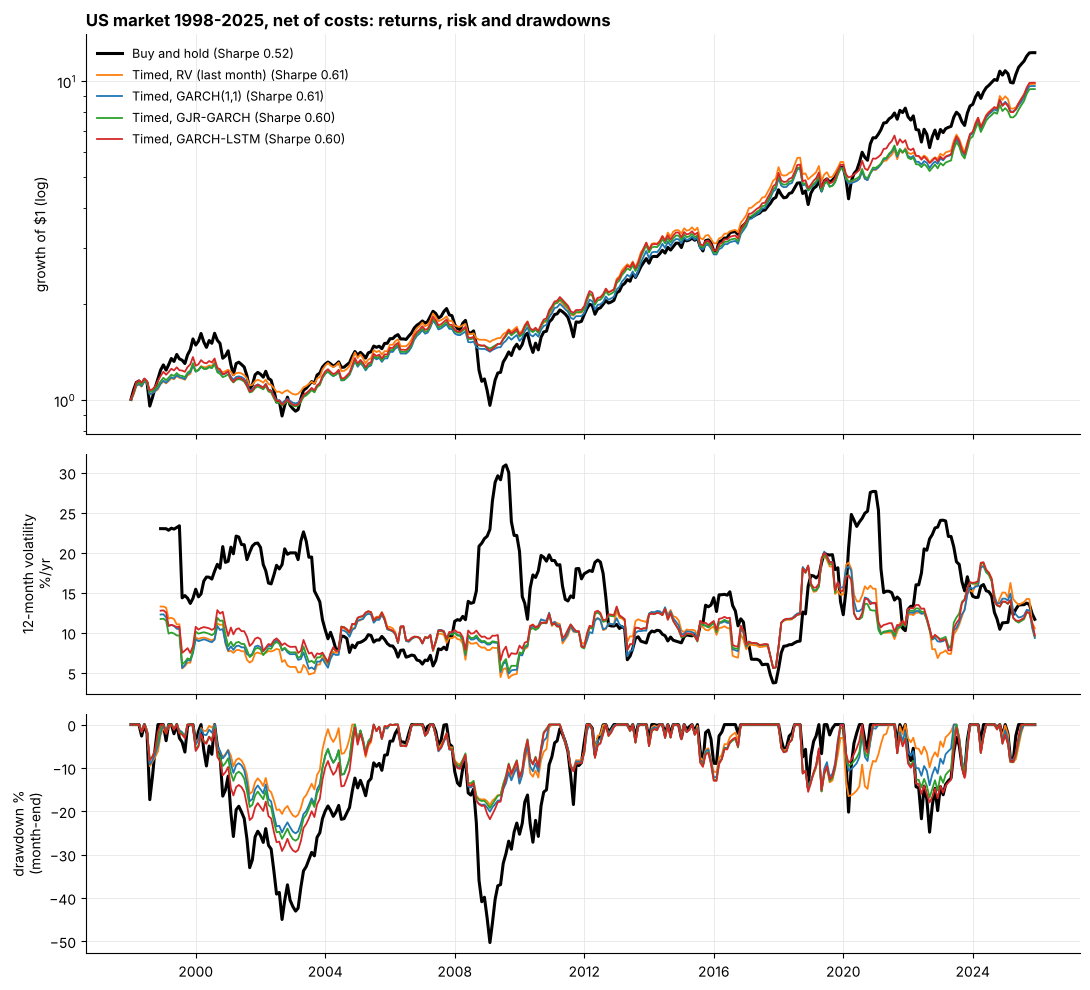

In [9]:
a, b = PERIODS[MAIN]
t = as_time(ret.loc[a:b].index)
fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1.2, 1.2]})
for k in MAIN_RULES:
    z = nets[k].loc[a:b]
    lw = 2.2 if k == "Buy and hold" else 1.3
    ax[0].plot(t, (1 + z + rf.loc[a:b]).cumprod(), color=COLORS[k], lw=lw, label=f"{k} (Sharpe {sharpe(z):.2f})")
    ax[1].plot(t, z.rolling(12).std() * 12 ** 0.5 * 100, color=COLORS[k], lw=lw)
    ax[2].plot(t, drawdown_path(z, rf.loc[a:b]), color=COLORS[k], lw=lw)
ax[0].set_yscale("log")
ax[0].set_ylabel("growth of $1 (log)")
ax[0].legend(frameon=False, fontsize=9)
ax[1].set_ylabel("12-month volatility\n%/yr")
ax[2].set_ylabel("drawdown %\n(month-end)")
ax[0].set_title("US market 1998-2025, net of costs: returns, risk and drawdowns", loc="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "fig03_growth_vol_drawdown.png", dpi=150)
plt.show()

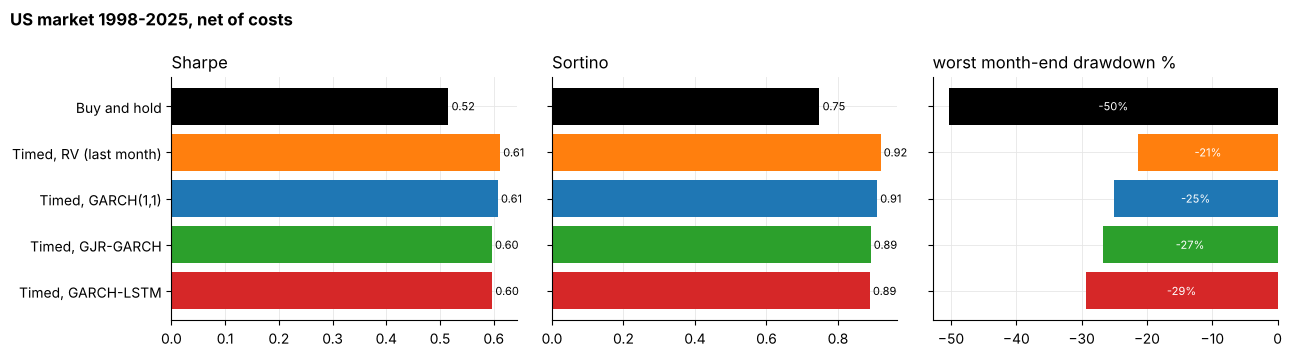

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for i, col in enumerate(["Sharpe", "Sortino", "max DD % (month-end)"]):
    ax[i].barh(scorecard.index, scorecard[col], color=[COLORS[k] for k in scorecard.index])
    for j, v in enumerate(scorecard[col]):
        ax[i].text(v if v >= 0 else v / 2, j, f" {v:.2f}" if i < 2 else f"{v:.0f}%", va="center", fontsize=8,
                   ha="left" if v >= 0 else "center", color="black" if v >= 0 else "white")
    ax[i].set_title({"max DD % (month-end)": "worst month-end drawdown %"}.get(col, col), loc="left")
    ax[i].invert_yaxis()
    if i > 0:
        ax[i].set_yticklabels([])
plt.suptitle("US market 1998-2025, net of costs", x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "fig03_scorecard.png", dpi=150)
plt.show()

**Reading the scorecard.** Every timed rule runs at 11.0-11.4% volatility against 15.9% for buy and hold and roughly
halves the worst month-end drawdown (-21.3% for RV, -25.1% GARCH, -26.8% GJR, -29.4% GARCH-LSTM, against -50.3%). The
Sharpe ratio rises from 0.516 to 0.597-0.612 and the Sortino ratio from 0.748 to 0.889-0.919, with an average exposure of
0.86-0.92 that exceeds 1 in 41-44% of months. The gains come from 1998-2015 (Sharpe 0.454-0.499 against 0.348); in
2016-2025 buy and hold does about as well (0.824 against 0.781-0.828). Lower volatility explains part of the smaller
drawdown: rescaled to buy and hold's volatility, the timed drawdowns are -32% to -42% (Section 3c).


**3b. Crises.** Total return over each crisis episode, as traded, and the exposure the rules held in the month after it
(when the rebound starts).

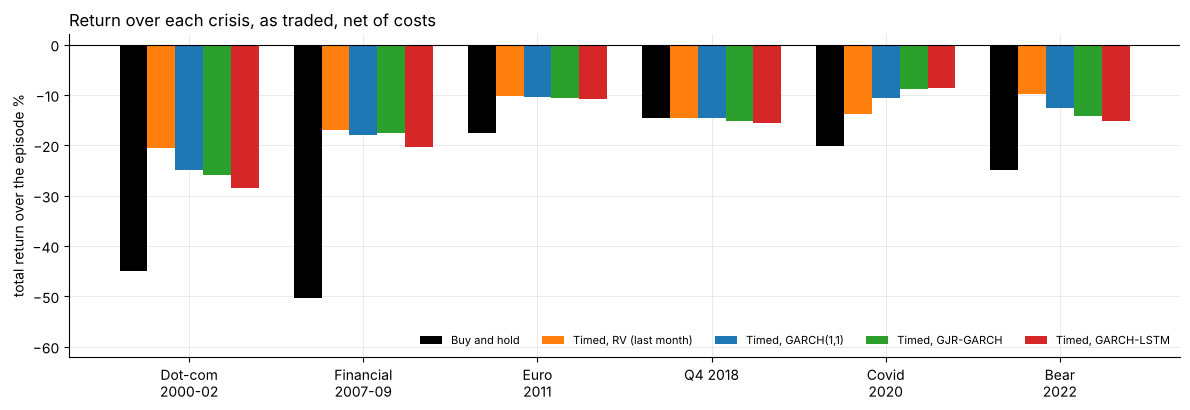

Return over each crisis, %:


,Buy and hold,"Timed, RV (last month)","Timed, GARCH(1,1)","Timed, GJR-GARCH","Timed, GARCH-LSTM"
Dot-com 2000-02,-44.978,-20.622,-24.901,-25.902,-28.421
Financial 2007-09,-50.306,-16.889,-17.997,-17.555,-20.282
Euro 2011,-17.649,-10.163,-10.515,-10.664,-10.787
Q4 2018,-14.527,-14.551,-14.584,-15.104,-15.528
Covid 2020,-20.198,-13.859,-10.649,-8.802,-8.716
Bear 2022,-24.829,-9.854,-12.639,-14.227,-15.175


Exposure in the month after each crisis:


,"Timed, RV (last month)","Timed, GARCH(1,1)","Timed, GJR-GARCH","Timed, GARCH-LSTM"
Dot-com 2000-02,0.177,0.199,0.180,0.194
Financial 2007-09,0.143,0.137,0.122,0.160
Euro 2011,0.192,0.198,0.173,0.185
Q4 2018,0.201,0.218,0.247,0.265
Covid 2020,0.020,0.034,0.035,0.054
Bear 2022,0.286,0.344,0.276,0.174


In [11]:
a, b = PERIODS[MAIN]
q1_names = ["Buy and hold"] + TIMED_MAIN


def episode_return(z, s, e):
    zz = z.loc[s:e]
    if len(zz) < len(rf.loc[s:e]):        # the series does not cover the whole episode
        return np.nan
    return 100 * ((1 + zz + rf.loc[s:e]).prod() - 1)


crisis_q1 = pd.DataFrame({k: {c: episode_return(nets[k].loc[a:b], s, e) for c, (s, e) in CRISES.items()} for k in q1_names})
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(CRISES))
wd = 0.8 / len(q1_names)
for i, k in enumerate(q1_names):
    ax.bar(x + (i - (len(q1_names) - 1) / 2) * wd, crisis_q1[k], wd, color=COLORS[k], label=k)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, list(CRISES))
ax.set_ylabel("total return over the episode %")
ax.set_title("Return over each crisis, as traded, net of costs", loc="left")
ax.set_ylim(-62, 2)
ax.legend(frameon=False, ncol=5, fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES / "fig03_crises.png", dpi=150)
plt.show()

after = pd.DataFrame({c.replace("\n", " "): {k: W[k].loc[e:].iloc[1] for k in TIMED_MAIN} for c, (s, e) in CRISES.items()}).T
print("Return over each crisis, %:")
display(crisis_q1.rename(index=lambda s: s.replace("\n", " ")))
print("Exposure in the month after each crisis:")
after

**Reading the crises.** The timed rules lost less than buy and hold in five of the six episodes, by the most in the
financial crisis (-17% to -20% against -50%) and the dot-com crash (-21% to -28% against -45%). In Covid the trained
models lost least (-8.7% GARCH-LSTM, -8.8% GJR against -20.2%). Q4 2018 is the exception: the fall was sudden, the rules
held 0.75-0.81 of the market during it, and every timed portfolio lost slightly more than the market (-14.6% to -15.5% against
-14.5%). After each crisis the rules held only 0.02-0.34 of the market, so they missed part of the rebound. These
comparisons are descriptive.


**3c. What improves, and is it significant?** Timing is meant to be a risk tool, so we test five measures, timed minus buy
and hold, 1998-2025:

- **Sharpe ratio.**
- **Sortino ratio:** mean excess return over downside deviation.
- **Worst drawdown at equal volatility:** the largest month-end fall after rescaling the timed series to buy and hold's
  volatility (so the comparison is not just "it holds less risk"). Positive gain = smaller loss.
- **Vol of vol at equal volatility:** the standard deviation of the 12-month rolling volatility, after the same rescaling.
  Smaller means the portfolio's own risk is steadier, which is what an investor with a fixed risk budget needs. Positive
  gain = steadier.
- **Certainty-equivalent return (CER):** mean − (γ/2)·variance with γ = 5, % a year.

**How we test.** A **paired circular block bootstrap** (Künsch, 1989; Politis and Romano, 1992): we resample the months
in blocks of 12 consecutive months (wrapping around the end) to build 5,000 new histories; both strategies use the same
blocks, so their correlation is kept. The 95% interval is the estimate plus or minus the 95th percentile of the absolute
bootstrap error, and the p-value is the share of absolute errors at least as large as the estimate. For the Sharpe ratio
we also use the **Ledoit and Wolf (2008) delta-method HAC test** (Bartlett weights, Newey and West, 1987; 5 lags for 336
months, Appendix E checks 0 to 12), and the **Romano and Wolf (2005) stepdown adjustment** for testing several rules at
once. Drawdowns depend on long runs of returns that 12-month blocks cut, so their p-values are only a rough guide.

In [12]:
SIG_RULES = TIMED_MAIN


x_, y_ = nets[TIMED["GARCH"]].loc["1998-01":], nets["Buy and hold"].loc["1998-01":]
assert np.isclose(ledoit_wolf_test(x_, y_)[0], -ledoit_wolf_test(y_, x_)[0])     # swapping flips the sign

rows = []
for p, (a, b) in PERIODS.items():
    u = nets["Buy and hold"].loc[a:b]
    for k in SIG_RULES:
        z = nets[k].loc[a:b]
        d, lo, hi, p_boot = bootstrap_test(z, u)
        _, se, p_lw = ledoit_wolf_test(z, u)
        rows.append({"period": p, "rule": k, "Sharpe gain": d, "bootstrap 95% CI": f"[{lo:+.2f}, {hi:+.2f}]",
                     "bootstrap p": p_boot, "Ledoit-Wolf s.e.": se, "Ledoit-Wolf p": p_lw})
significance = pd.DataFrame(rows).set_index(["period", "rule"])
for p, (a, b) in PERIODS.items():           # family = the rules tested in one period
    rw = romano_wolf({k: (nets[k].loc[a:b], nets["Buy and hold"].loc[a:b]) for k in SIG_RULES})
    significance.loc[p, "Romano-Wolf p"] = rw.to_numpy()
significance

Sharpe gain bootstrap 95% CI  bootstrap p  Ledoit-Wolf s.e.  Ledoit-Wolf p  Romano-Wolf p
period    rule                                                                                                             
1998-2025 Timed, RV (last month)        0.096   [-0.17, +0.37]        0.478             0.140          0.491          0.608
          Timed, GARCH(1,1)             0.092   [-0.14, +0.32]        0.439             0.128          0.473          0.586
          Timed, GJR-GARCH              0.081   [-0.16, +0.32]        0.505             0.130          0.532          0.608
          Timed, GARCH-LSTM             0.081   [-0.14, +0.30]        0.479             0.120          0.497          0.608
1998-2015 Timed, RV (last month)        0.151   [-0.14, +0.44]        0.303             0.175          0.386          0.416
          Timed, GARCH(1,1)             0.111   [-0.16, +0.38]        0.414             0.162          0.493          0.484
          Timed, GJR-GARCH              0.111   [-0.16, +0.39]        0.429             0.163          0.496          0.484
          Timed, GARCH-LSTM             0.106   [-0.15, +0.36]        0.414             0.151          0.480          0.484
2016-2025 Timed, RV (last month)       -0.043   [-0.47, +0.39]        0.850             0.198          0.828          0.963
          Timed, GARCH(1,1)             0.004   [-0.35, +0.36]        0.980             0.185          0.981          0.998
          Timed, GJR-GARCH             -0.020   [-0.38, +0.34]        0.905             0.191          0.915          0.984
          Timed, GARCH-LSTM            -0.008   [-0.34, +0.33]        0.961             0.181          0.964          0.998
2021-2025 Timed, RV (last month)        0.148   [-0.36, +0.65]        0.514             0.257          0.560          0.680
          Timed, GARCH(1,1)             0.120   [-0.29, +0.53]        0.483             0.215          0.573          0.680
          Timed, GJR-GARCH              0.054   [-0.32, +0.43]        0.741             0.216          0.800          0.794
          Timed, GARCH-LSTM             0.016   [-0.33, +0.36]        0.922             0.210          0.940          0.922

In [13]:
def sortino_gain(X):
    return sortino(X[:, 0]) - sortino(X[:, 1])


def drawdown_gain_equal_vol(X):
    z, u, r_f = X[:, 0], X[:, 1], X[:, 2]
    return max_drawdown(z * u.std(ddof=1) / z.std(ddof=1), r_f) - max_drawdown(u, r_f)


def volvol_gain(X):
    # buy-and-hold minus timed vol of vol, with the timed series re-scaled to equal volatility inside every draw
    z, u = X[:, 0], X[:, 1]
    return vol_of_vol(u) - vol_of_vol(z * u.std(ddof=1) / z.std(ddof=1))


def cer_gain(X):
    return cer(X[:, 0]) - cer(X[:, 1])


a, b = PERIODS[MAIN]
u = nets["Buy and hold"].loc[a:b]
MEASURES = {"Sharpe": (lambda X: sharpe(X[:, 0]) - sharpe(X[:, 1]), False), "Sortino": (sortino_gain, False), "max DD at equal vol, pts": (drawdown_gain_equal_vol, True),
            "vol of vol at equal vol, pts": (volvol_gain, False), "CER, %/yr": (cer_gain, False)}
rows, ci = {}, {}
for k in SIG_RULES:
    z = nets[k].loc[a:b]
    rows[k] = {}
    for m, (fn, needs_rf) in MEASURES.items():
        X = paired(z, u, rf.loc[a:b]) if needs_rf else paired(z, u)
        est, lo, hi, p = bootstrap(X, fn)
        scale = 100 if m.startswith("max DD") else 1
        rows[k][f"{m} gain"] = scale * est
        rows[k][f"{m} 95% CI"] = f"[{scale * lo:+.2f}, {scale * hi:+.2f}]"
        rows[k][f"{m} p"] = p
        ci[(k, m)] = (scale * est, scale * lo, scale * hi)
investor = pd.DataFrame(rows).T
levels = pd.DataFrame({k: {"Sortino": sortino(nets[k].loc[a:b]),
                           "max DD % (equal vol)": 100 * max_drawdown(same_vol_as(nets[k].loc[a:b], u), rf.loc[a:b]),
                           "vol of vol % (as traded)": vol_of_vol(nets[k].loc[a:b]),
                           "vol of vol % (equal vol)": vol_of_vol(same_vol_as(nets[k].loc[a:b], u)), "CER %/yr": cer(nets[k].loc[a:b])}
                       for k in ["Buy and hold"] + SIG_RULES}).T
print("Levels, 1998-2025:")
display(levels)
investor

Levels, 1998-2025:


,Sortino,max DD % (equal vol),vol of vol % (as traded),vol of vol % (equal vol),CER %/yr
Buy and hold,0.748,-50.306,5.756,5.756,1.870
"Timed, RV (last month)",0.919,-32.040,3.152,4.565,3.705
"Timed, GARCH(1,1)",0.909,-36.858,2.889,4.191,3.658
"Timed, GJR-GARCH",0.891,-39.753,2.753,3.961,3.540
"Timed, GARCH-LSTM",0.889,-41.774,2.619,3.662,3.559


,Sharpe gain,Sharpe 95% CI,Sharpe p,Sortino gain,Sortino 95% CI,Sortino p,"max DD at equal vol, pts gain","max DD at equal vol, pts 95% CI","max DD at equal vol, pts p","vol of vol at equal vol, pts gain","vol of vol at equal vol, pts 95% CI","vol of vol at equal vol, pts p","CER, %/yr gain","CER, %/yr 95% CI","CER, %/yr p"
"Timed, RV (last month)",0.096,"[-0.17, +0.37]",0.478,0.171,"[-0.31, +0.66]",0.483,18.267,"[-2.66, +39.19]",0.097,1.191,"[-0.23, +2.61]",0.094,1.835,"[-2.84, +6.51]",0.437
"Timed, GARCH(1,1)",0.092,"[-0.14, +0.32]",0.439,0.161,"[-0.26, +0.58]",0.446,13.449,"[-4.18, +31.07]",0.143,1.565,"[+0.13, +3.00]",0.033,1.788,"[-2.48, +6.05]",0.409
"Timed, GJR-GARCH",0.081,"[-0.16, +0.32]",0.505,0.143,"[-0.28, +0.57]",0.507,10.553,"[-7.10, +28.20]",0.259,1.795,"[+0.34, +3.25]",0.015,1.670,"[-2.59, +5.93]",0.435
"Timed, GARCH-LSTM",0.081,"[-0.14, +0.30]",0.479,0.141,"[-0.25, +0.54]",0.487,8.532,"[-8.56, +25.63]",0.353,2.095,"[+0.62, +3.57]",0.005,1.689,"[-2.28, +5.66]",0.396


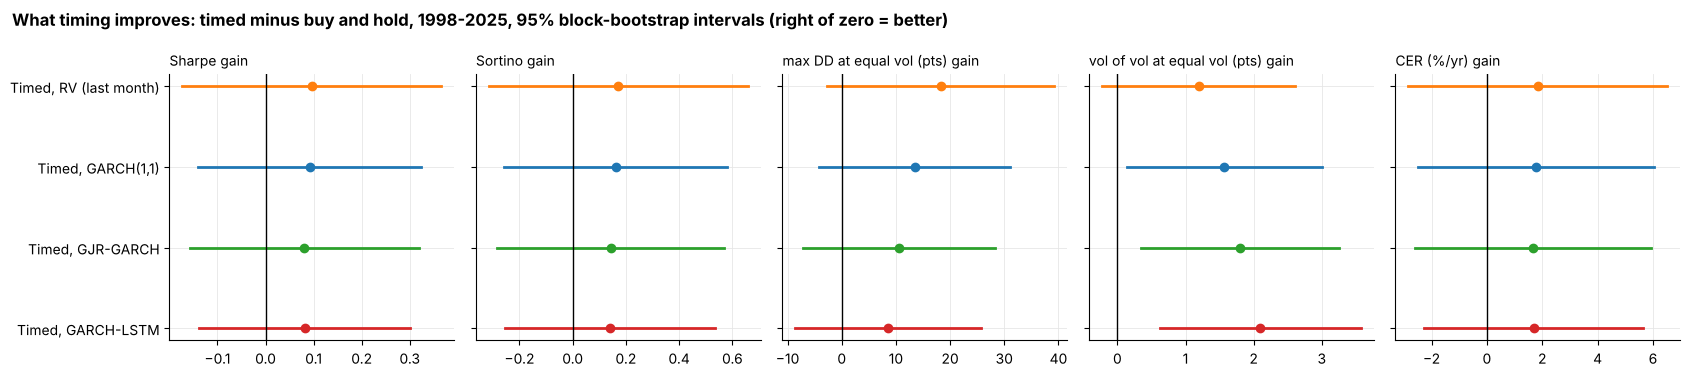

In [14]:
fig, ax = plt.subplots(1, 5, figsize=(17, 3.8), sharey=True)
for i, m in enumerate(MEASURES):
    for j, k in enumerate(SIG_RULES):
        est, lo, hi = ci[(k, m)]
        col = COLORS.get(k, "grey")
        ax[i].plot([lo, hi], [j, j], color=col, lw=2)
        ax[i].plot(est, j, "o", color=col)
    ax[i].axvline(0, color="black", lw=1)
    ax[i].set_title(m.replace(", pts", " (pts)").replace(", %/yr", " (%/yr)") + " gain", loc="left", fontsize=10)
ax[0].set_yticks(range(len(SIG_RULES)), SIG_RULES)
ax[0].invert_yaxis()
plt.suptitle("What timing improves: timed minus buy and hold, 1998-2025, 95% block-bootstrap intervals (right of zero = better)",
             x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "fig03_what_improves.png", dpi=150)
plt.show()

**3d. Sharpe differences by subperiod.** Paired bootstrap intervals for 1998-2015 and 2016-2025. The point gains are
+0.11 to +0.15 in 1998-2015 and -0.04 to 0.00 in 2016-2025; every interval includes zero.


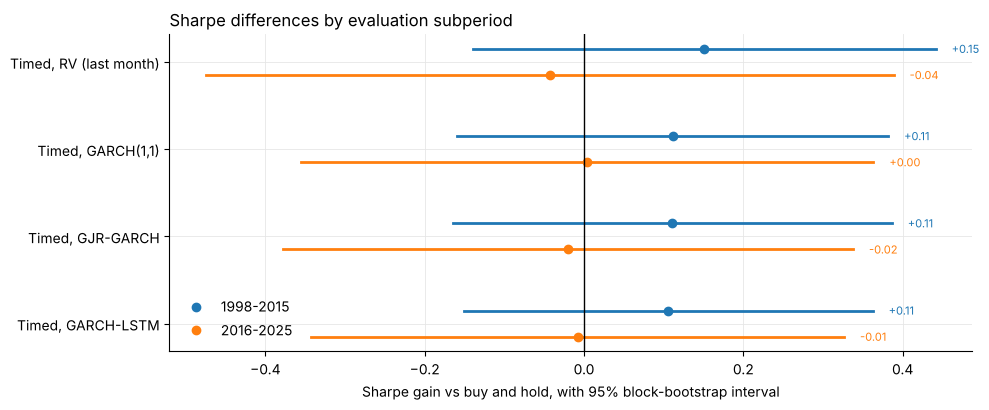

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for j, (p, col) in enumerate([("1998-2015", "tab:blue"), ("2016-2025", "tab:orange")]):
    a, b = PERIODS[p]
    for i, k in enumerate(SIG_RULES):
        d, lo, hi, _ = bootstrap_test(nets[k].loc[a:b], nets["Buy and hold"].loc[a:b])
        y = i + (j - 0.5) * 0.3
        ax.plot([lo, hi], [y, y], color=col, lw=2)
        ax.plot(d, y, "o", color=col, label=p if i == 0 else None)
        ax.text(hi + 0.02, y, f"{d:+.2f}", va="center", fontsize=8, color=col)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(SIG_RULES)), SIG_RULES)
ax.invert_yaxis()
ax.set_xlabel("Sharpe gain vs buy and hold, with 95% block-bootstrap interval")
ax.set_title("Sharpe differences by evaluation subperiod", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURES / "fig03_sharpe_by_period.png", dpi=150)
plt.show()


**Answering Q1: timing is a risk tool, not a return enhancer.**

- **Sharpe and CER: not significant.** The Sharpe gain is +0.08 to +0.10 (bootstrap p 0.44-0.51, Ledoit-Wolf p
  0.47-0.53, Romano-Wolf p 0.59-0.61), the Sortino gain +0.14 to +0.17 (p 0.45-0.51) and the CER gain +1.7 to +1.8% a
  year (p 0.40-0.44). With 336 months the standard error of a Sharpe difference is about 0.12-0.14.
- **Drawdown at equal volatility: smaller, but uncertain.** 8.5 to 18.3 points smaller (p 0.10-0.35, a rough guide
  because 12-month blocks cut long runs).
- **Steadier risk: the one gain at the 5% level.** Vol of vol at equal volatility is 1.2 to 2.1 points lower; p is
  0.033 for GARCH(1,1), 0.015 for GJR and 0.005 for the GARCH-LSTM (0.094 for RV). These p-values are unadjusted.

The rules cut risk reliably; whether they also improve return per unit of risk depends on the period and is not
established.


## 4. Q2: Does forecast accuracy translate into portfolio performance?

Compare statistical forecasts with the performance of their primary portfolios. All methods use the same market returns,
evaluation dates, cap and transaction-cost convention, but the unchanged benchmarks and trained portfolios retain their
distinct estimation/calibration histories. This is a descriptive comparison across procedures, not an isolated causal
test of forecast quality alone.

The gross Sharpe ratio decomposes as

$$\frac{SR_{timed}}{SR_{buy\ and\ hold}}=MT\times VT,\quad
MT=\frac{E[xR]}{E[R]},\quad VT=\frac{sd(R)}{sd(xR)},$$

where x is exposure divided by its sample mean and R is excess return. MT describes return alignment; VT describes
variance reduction after normalizing mean exposure. The identity is gross of costs. Read forecast ranks from QLIKE,
then compare net Sharpe, Sortino, MT/VT and drawdown; the rankings need not coincide.


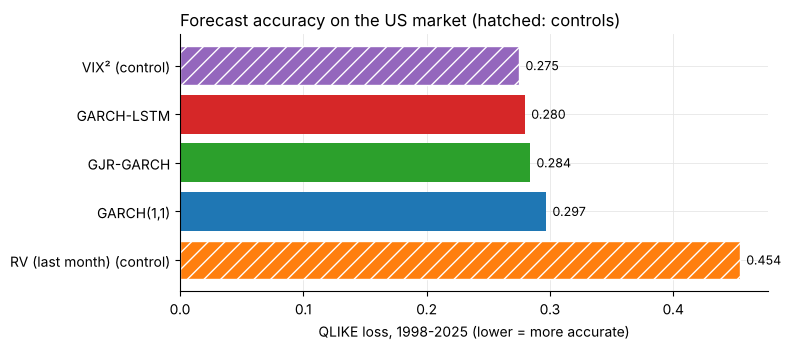

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = accuracy.sort_values(ascending=False).index
bars = ax.barh([LABEL[k] + (" (control)" if k in CONTROLS else "") for k in order], accuracy[order],
               color=[COLORS[k] for k in order], hatch=None)
for bar, k in zip(bars, order):
    if k in CONTROLS:
        bar.set_hatch("//")
        bar.set_edgecolor("white")
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2, f"{accuracy[k]:.3f}", va="center", fontsize=9)
ax.set_xlabel("QLIKE loss, 1998-2025 (lower = more accurate)")
ax.set_title("Forecast accuracy on the US market (hatched: controls)", loc="left")
plt.tight_layout()
plt.savefig(FIGURES / "fig04_qlike.png", dpi=150)
plt.show()

In [17]:
a, b = PERIODS[MAIN]
u = nets["Buy and hold"].loc[a:b]
by_accuracy = accuracy.sort_values(ascending=False).index          # least accurate first
rows = {"Buy and hold": {"QLIKE": np.nan, "Sharpe (net)": sharpe(u), "Sortino (net)": sortino(u), "Sharpe (gross)": sharpe(u),
                         "MT (gross)": 1.0, "VT (gross)": 1.0, "MT x VT": 1.0,
                         "max DD % (same vol)": 100 * max_drawdown(u, rf.loc[a:b])}}
for k in by_accuracy:
    z, w = nets[TIMED[k]].loc[a:b], W[TIMED[k]].loc[a:b]
    mt, vt = mt_vt(w, mkt.loc[a:b])
    name = LABEL[k] + (" = Moreira-Muir rule" if k == "RV" else " (control)" if k == "VIX2" else "")
    rows[name] = {"QLIKE": accuracy[k], "Sharpe (net)": sharpe(z), "Sortino (net)": sortino(z),
                  "Sharpe (gross)": sharpe(w * mkt.loc[a:b]), "MT (gross)": mt, "VT (gross)": vt, "MT x VT": mt * vt,
                  "max DD % (same vol)": 100 * max_drawdown(same_vol_as(z, u), rf.loc[a:b])}
ablation_forecast = pd.DataFrame(rows).T
ablation_forecast

,QLIKE,Sharpe (net),Sortino (net),Sharpe (gross),MT (gross),VT (gross),MT x VT,max DD % (same vol)
Buy and hold,NaN,0.516,0.748,0.516,1.000,1.000,1.000,-50.306
RV (last month) = Moreira-Muir rule,0.454,0.612,0.919,0.646,1.006,1.245,1.252,-32.040
"GARCH(1,1)",0.297,0.608,0.909,0.637,0.974,1.269,1.236,-36.858
GJR-GARCH,0.284,0.597,0.891,0.628,0.948,1.285,1.218,-39.753
GARCH-LSTM,0.280,0.597,0.889,0.629,0.949,1.285,1.219,-41.774
VIX² (control),0.275,0.545,0.791,0.558,0.896,1.207,1.081,-46.272


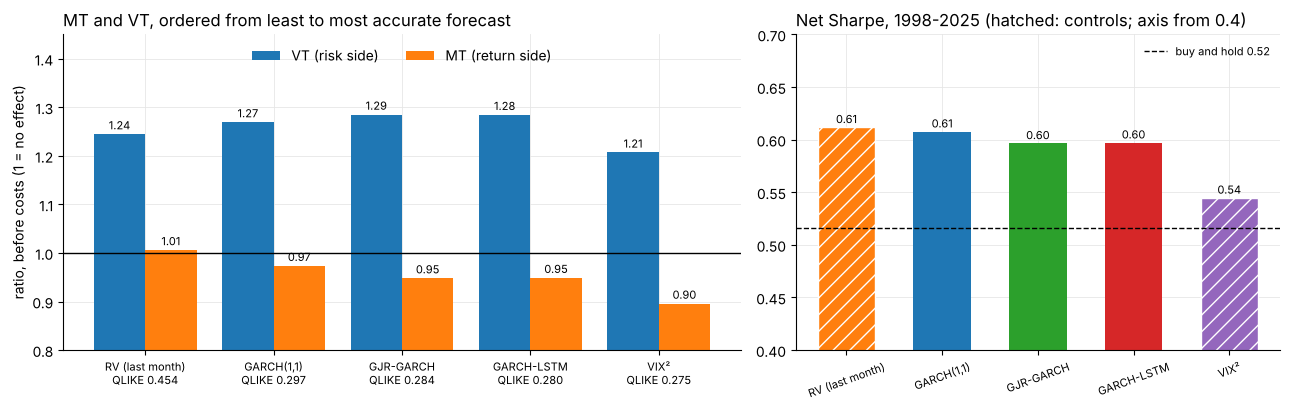

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
fc = ablation_forecast.drop("Buy and hold")
x = np.arange(len(fc))
names = [LABEL[k] for k in by_accuracy]
ax[0].bar(x - 0.2, fc["VT (gross)"], 0.4, label="VT (risk side)", color="tab:blue")
ax[0].bar(x + 0.2, fc["MT (gross)"], 0.4, label="MT (return side)", color="tab:orange")
for i, (vt, mt) in enumerate(zip(fc["VT (gross)"], fc["MT (gross)"])):
    ax[0].text(i - 0.2, vt + 0.01, f"{vt:.2f}", ha="center", fontsize=8)
    ax[0].text(i + 0.2, mt + 0.01, f"{mt:.2f}", ha="center", fontsize=8)
ax[0].axhline(1, color="black", lw=1)
ax[0].set_xticks(x, [f"{n}\nQLIKE {q:.3f}" for n, q in zip(names, fc["QLIKE"])], fontsize=8)
ax[0].set_ylim(0.8, 1.45)
ax[0].set_ylabel("ratio, before costs (1 = no effect)")
ax[0].set_title("MT and VT, ordered from least to most accurate forecast", loc="left")
ax[0].legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
bars = ax[1].bar(x, fc["Sharpe (net)"], 0.6, color=[COLORS[k] for k in by_accuracy])
for bar, k in zip(bars, by_accuracy):
    if k in CONTROLS:
        bar.set_hatch("//")
        bar.set_edgecolor("white")
for i, v in enumerate(fc["Sharpe (net)"]):
    ax[1].text(i, v + 0.004, f"{v:.2f}", ha="center", fontsize=8)
ax[1].axhline(sharpe(u), color="black", ls="--", lw=1, label=f"buy and hold {sharpe(u):.2f}")
ax[1].set_xticks(x, names, fontsize=8, rotation=20)
ax[1].set_ylim(0.4, 0.7)
ax[1].set_title("Net Sharpe, 1998-2025 (hatched: controls; axis from 0.4)", loc="left")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "fig04_mt_vt.png", dpi=150)
plt.show()

**Answering Q2: no, a more accurate forecast did not give a better portfolio.** The accuracy ranking (VIX² 0.275,
GARCH-LSTM 0.280, GJR 0.284, GARCH 0.297, RV 0.454) is close to the reverse of the Sharpe ranking (RV 0.612, GARCH 0.608,
GJR 0.597, GARCH-LSTM 0.597, VIX² 0.545). The extremes make the point: the least accurate forecast, last month's RV, gives
the highest Sharpe, and the most accurate, VIX², the lowest. Among the three models the differences are small (Sharpe
0.597-0.608).

The decomposition shows why. Variance timing works for every forecast (VT 1.21-1.29), but mean timing falls as forecasts
become more informative: MT is 1.006 for RV, 0.974 for GARCH, 0.95 for GJR and the GARCH-LSTM and 0.896 for VIX². The rule
assumes the expected return is constant, so a sharper variance forecast cuts exposure more in high-variance months, and
those months include the best-paying recoveries (Section 5).

Caveats: five forecasts are a small sample, and the procedures differ in estimation and calibration history, so this is
an association, not proof that accuracy causes lower Sharpe ratios.


## 5. Predictability and recovery states

A simplified mean-variance exposure is proportional to expected excess return divided by variance. Inverse-variance
timing treats the numerator as constant. The following unchanged diagnostic regressions compare variance and return
forecasting with expanding historical-average benchmarks. Returns use lagged return/trend/variance signals; variance
uses log reconstructed RV and log forecasts. Different forecast availability creates different pre-test regression
histories. The Clark-West calculation retains the original implementation and should not be read as proving that
returns are inherently unpredictable.


In [19]:
def oos_forecasts(y, x, first="1970-01", start=PERIODS[MAIN][0], end=PERIODS[MAIN][1]):
    """Real-time expanding-window regression y_t = a + b x_t (x_t known at the end of month t-1). Each month uses only
    earlier months. Returns the forecasts and the historical-average benchmark for start..end."""
    d = pd.DataFrame({"y": y, "x": x}).loc[first:end].dropna()
    pred, bench = {}, {}
    for t in d.loc[start:end].index:
        tr = d.loc[:t].iloc[:-1]
        slope, intercept = np.polyfit(tr["x"], tr["y"], 1)
        pred[t], bench[t] = intercept + slope * d.at[t, "x"], tr["y"].mean()
    return pd.Series(pred), pd.Series(bench)


def oos_r2(y, pred, bench):
    """Out-of-sample R² (%) against the historical average, and the one-sided Clark-West (2007) p-value."""
    y = y.reindex(pred.index)
    e_p, e_b = y - pred, y - bench
    f = e_b ** 2 - (e_p ** 2 - (bench - pred) ** 2)
    t_cw = f.mean() / (f.std(ddof=1) / np.sqrt(len(f)))
    return 100 * (1 - (e_p ** 2).sum() / (e_b ** 2).sum()), 1 - norm.cdf(t_cw)


# variance: log realised variance on the log of each forecast
log_rv = np.log(rv_eval["Mkt-RF"])
var_rows = {}
for k in FORECASTS:
    p_, b_ = oos_forecasts(log_rv, np.log(forecasts[k]))
    r2, p_cw = oos_r2(log_rv, p_, b_)
    var_rows[LABEL[k]] = {"out-of-sample R² %": r2, "Clark-West p": p_cw}
var_oos = pd.DataFrame(var_rows).T

# returns: standard predictors, their average, and the Campbell-Thompson sign restriction
predictors = {"last month's return": mkt.shift(1), "past 12 months' return": mkt.rolling(12).sum().shift(1),
              "GARCH(1,1) variance forecast": forecasts["GARCH"]}
ret_preds, ret_rows = {}, {}
for name, x in predictors.items():
    p_, b_ = oos_forecasts(mkt, x)
    ret_preds[name], bench_ret = p_, b_
    r2, p_cw = oos_r2(mkt, p_, b_)
    ret_rows[name] = {"out-of-sample R² %": r2, "Clark-West p": p_cw}
combo = pd.concat(ret_preds, axis=1).mean(axis=1)
for name, p_ in {"average of the three (Rapach et al.)": combo,
                 "average, forecast ≥ 0 (Campbell-Thompson)": combo.clip(lower=0)}.items():
    r2, p_cw = oos_r2(mkt, p_, bench_ret)
    ret_rows[name] = {"out-of-sample R² %": r2, "Clark-West p": p_cw}
ret_oos = pd.DataFrame(ret_rows).T
print("Out-of-sample R², 1998-2025, against the historical average (real-time, expanding window from 1970)")
print("Next month's log realised variance:")
display(var_oos)
print("Next month's market excess return:")
ret_oos


Out-of-sample R², 1998-2025, against the historical average (real-time, expanding window from 1970)
Next month's log realised variance:


,out-of-sample R² %,Clark-West p
"GARCH(1,1)",53.115,0.000
GJR-GARCH,53.560,0.000
GARCH-LSTM,53.637,0.000
RV (last month),47.117,0.000
VIX²,57.080,0.000


Next month's market excess return:


,out-of-sample R² %,Clark-West p
last month's return,-0.287,0.427
past 12 months' return,-0.270,0.625
"GARCH(1,1) variance forecast",-2.092,0.600
average of the three (Rapach et al.),-0.560,0.569
"average, forecast ≥ 0 (Campbell-Thompson)",-0.191,0.567


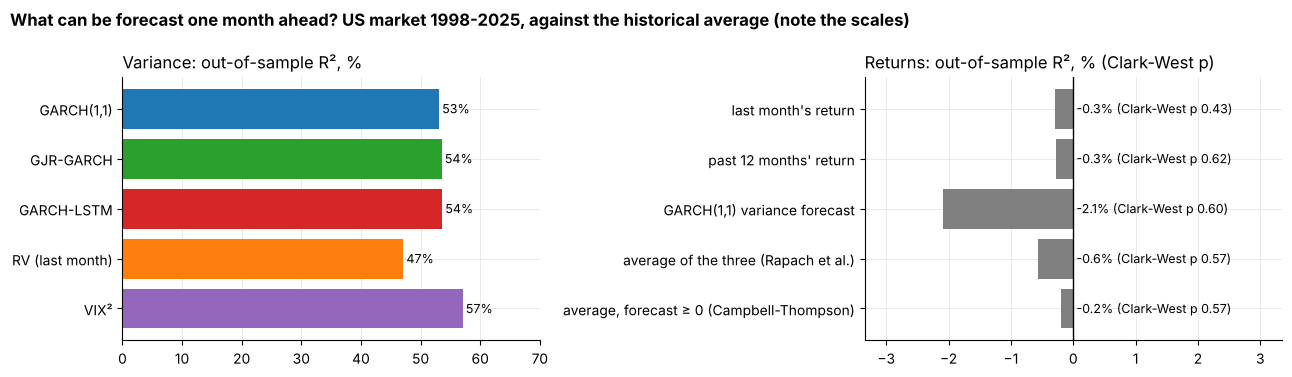

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].barh(var_oos.index, var_oos["out-of-sample R² %"], color=[COLORS[k] for k in FORECASTS])
for j, v in enumerate(var_oos["out-of-sample R² %"]):
    ax[0].text(v + 0.5, j, f"{v:.0f}%", va="center", fontsize=9)
ax[0].set_xlim(0, 70)
ax[0].invert_yaxis()
ax[0].set_title("Variance: out-of-sample R², %", loc="left")
cols = ["tab:orange" if v >= 0 else "grey" for v in ret_oos["out-of-sample R² %"]]
ax[1].barh(ret_oos.index, ret_oos["out-of-sample R² %"], color=cols)
for j, (v, p) in enumerate(zip(ret_oos["out-of-sample R² %"], ret_oos["Clark-West p"])):
    ax[1].text(max(v, 0) + 0.05, j, f"{v:+.1f}% (Clark-West p {p:.2f})", va="center", fontsize=9, ha="left")
ax[1].axvline(0, color="black", lw=1)
lim = max(3, 1.6 * ret_oos["out-of-sample R² %"].abs().max())
ax[1].set_xlim(-lim, lim)
ax[1].invert_yaxis()
ax[1].set_title("Returns: out-of-sample R², % (Clark-West p)", loc="left")
plt.suptitle("What can be forecast one month ahead? US market 1998-2025, against the historical average (note the scales)",
             x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "fig05_predictability.png", dpi=150)
plt.show()

**Reading the predictability tables.** Variance is highly predictable: out-of-sample R² for log realised variance is 47%
(RV) to 57% (VIX²), 53-54% for the three models (Clark-West p < 0.001). Market returns are not, with these predictors:
last month's return, the past year's return, the GARCH variance forecast and their combinations all do worse than the
historical average (R² -0.2% to -2.1%, Clark-West p 0.43-0.63). This failure of the tested predictors is not proof that
every return predictor fails. The recovery-state exercise below is exploratory and its intervals are explicitly naive.


In [21]:
def short_long_var(r_daily, months):
    # 5-day and 63-day realised variance at the end of the previous month, scaled to a month
    month_end = r_daily.groupby(r_daily.index.to_period("M")).apply(lambda z: z.index[-1])
    out = []
    for k in (5, 63):
        v = (r_daily ** 2).rolling(k).sum() * 21 / k
        out.append(pd.Series(v.loc[month_end.values].to_numpy(), index=month_end.index.astype(str)).shift(1).reindex(months))
    return out


rv5, rv63 = short_long_var(r_mkt.dropna(), ret.index)
rv_last = forecasts["RV"]
q80 = rv_last.expanding(120).quantile(0.8)
state = pd.Series("Normal", index=ret.index).where(rv_last <= q80, "Panic")
state[(rv_last > q80) & (rv5 < rv63)] = "Recovery"
state[q80.isna()] = None

d = pd.DataFrame({"state": state, "ret": mkt, "w": W[TIMED["RV"]]}).loc["1975-01":"2025-12"].dropna()
states = d.groupby("state").agg(months=("ret", "size"), return_pct=("ret", "mean"), sd=("ret", "std"),
                                exposure=("w", "mean")).loc[["Normal", "Panic", "Recovery"]]
states["return_pct"] *= 100
states["naive 95% interval +/-"] = 196 * states.pop("sd") / np.sqrt(states["months"])   # treats months as independent
for p_ in [("1975-01", "2025-12"), PERIODS[MAIN]]:
    print(f"MT (gross) of timing on RV, {p_[0][:4]}-{p_[1][:4]}: {mt_vt(W[TIMED['RV']].loc[p_[0]:p_[1]], mkt.loc[p_[0]:p_[1]])[0]:.3f}")
states

MT (gross) of timing on RV, 1975-2025: 0.897
MT (gross) of timing on RV, 1998-2025: 1.006


,months,return_pct,exposure,naive 95% interval +/-
state,,,,
Normal,434,0.639,1.204,0.359
Panic,81,0.367,0.338,1.260
Recovery,97,1.586,0.351,1.156


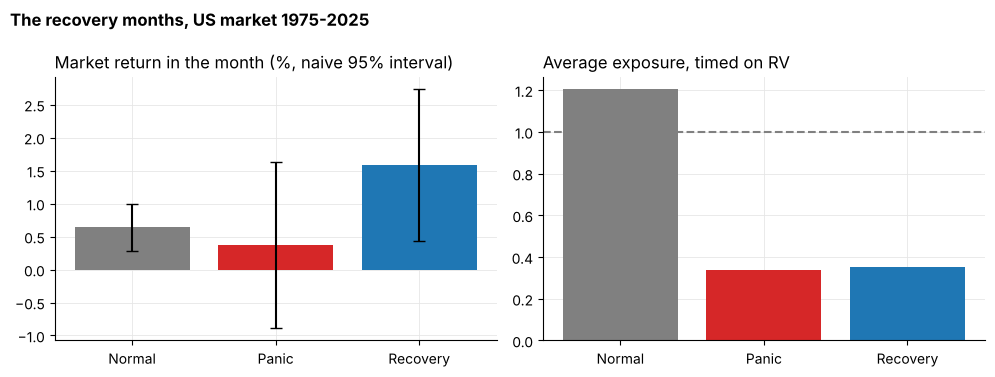

Sharpe 1998-2025: buy and hold 0.52, timed on RV 0.61, with the recovery fix 0.59


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
colors = ["grey", "tab:red", "tab:blue"]
ax[0].bar(states.index, states["return_pct"], yerr=states["naive 95% interval +/-"], color=colors, capsize=4)
ax[0].set_title("Market return in the month (%, naive 95% interval)", loc="left")
ax[1].bar(states.index, states["exposure"], color=colors)
ax[1].axhline(1, color="grey", ls="--")
ax[1].set_title("Average exposure, timed on RV", loc="left")
plt.suptitle("The recovery months, US market 1975-2025", x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "fig05_recovery.png", dpi=150)
plt.show()

# as an exploratory fix, hold at least full exposure in recovery months
w_fix = W[TIMED["RV"]].where(state != "Recovery", np.maximum(W[TIMED["RV"]], 1.0)).clip(0, CAP)
W["Recovery fix"] = w_fix
nets["Recovery fix"] = backtest(w_fix.loc["1970-01":], mkt)
a, b = PERIODS[MAIN]
print(f"Sharpe 1998-2025: buy and hold {sharpe(nets['Buy and hold'].loc[a:b]):.2f}, "
      f"timed on RV {sharpe(nets[TIMED['RV']].loc[a:b]):.2f}, with the recovery fix {sharpe(nets['Recovery fix'].loc[a:b]):.2f}")

**Reading the states (1975-2025).** Recovery months (high variance that is already falling) return 1.59% a month on
average, against 0.64% in normal months and 0.37% in panic months, yet the rule holds only 0.35 of the market in them
(1.20 in normal months). The recovery estimate is imprecise (naive interval +/- 1.16 points). This is why mean timing is
below 1 over 1975-2025 (MT 0.897), although close to 1 in 1998-2025 (1.006). Holding at least full exposure in recovery
months does not help: the Sharpe ratio falls from 0.61 to 0.59, because the extra return comes with more risk. The
exercise was designed after seeing the pattern, so it is a diagnostic, not a strategy.


## 6. Q3: Does decision-focused training help?

One GJR architecture and one GJR-based LSTM architecture each have two objectives. Acc minimizes the statistical
loss; Dec maximizes net second-moment utility

$$E[R^{net}]-\frac{\gamma}{2}E[(R^{net})^2],\qquad\gamma=5.$$

Read both variants from the completed revised run. Acc and Dec share the model/data/protocol within each architecture.
The primary LSTM ensemble averages variance forecasts before allocation; use its exported exposure, not a mean of
seed exposures. The same market Acc forecasts and weights appear in Q1/Q2 and the exposure plots.

The revised training separates fitting from five-calendar-year validation, initializes freshly, and retains selected
checkpoints without a full-history refit. Its annual c replay and forward calibration are described in Section 2.
The neural monthly horizon is still a GJR-recursion approximation. No additional training is performed here.

Judge Dec primarily on its exact out-of-sample training objective; Sharpe is secondary and QLIKE is a diagnostic.
Mean-variance CER in Q1 is related but not identical to the second-moment objective. Best-constant QLIKE rescaling is
an explicitly retrospective diagnostic; it does not change the traded exposures.


In [23]:
def realised_utility(z, gamma=GAMMA):
    # the decision objective, evaluated out of sample: mean(R) - gamma/2 mean(R^2), % a year
    z = np.asarray(z, float)
    return 1200 * (z.mean() - gamma / 2 * np.mean(z ** 2))


a, b = PERIODS[MAIN]
dfl_sharpe, dfl_util, dfl_qlike, dfl_qlike_scaled, dfl_nets = {}, {}, {}, {}, {}
for f, g in lstm_files.items():
    dfl_nets[(f, "Buy and hold")] = g["f"]
    for name, col in DFL_MODELS.items():
        dfl_nets[(f, name)] = backtest(g[f"W_{col}"], g["f"])
    dfl_sharpe[f] = {k: sharpe(dfl_nets[(f, k)].loc[a:b]) for k in ["Buy and hold", *DFL_MODELS]}
    dfl_util[f] = {k: realised_utility(dfl_nets[(f, k)].loc[a:b]) for k in ["Buy and hold", *DFL_MODELS]}
    gg = g.loc[a:b]
    dfl_qlike[f] = {k: qlike(gg[f"V_{c}"], gg["rv"]) for k, c in DFL_MODELS.items()}
    dfl_qlike_scaled[f] = {k: qlike(gg[f"V_{c}"] * (gg["rv"] / gg[f"V_{c}"]).mean(), gg["rv"])
                        for k, c in DFL_MODELS.items()}
dfl_sharpe, dfl_util = pd.DataFrame(dfl_sharpe).T, pd.DataFrame(dfl_util).T
dfl_qlike, dfl_qlike_scaled = pd.DataFrame(dfl_qlike).T, pd.DataFrame(dfl_qlike_scaled).T
print("Decision metric 1: net Sharpe ratio, 1998-2025")
display(dfl_sharpe)
print("Decision metric 2: realised training objective mean(R) - (γ/2) mean(R²), γ = 5, % a year, 1998-2025")
display(dfl_util)
print("Diagnostic: QLIKE of the actual model or forecast ensemble, lower is better")
display(dfl_qlike)
print("Diagnostic: QLIKE after rescaling each forecast by its best constant (ex post)")
dfl_qlike_scaled


Decision metric 1: net Sharpe ratio, 1998-2025


,Buy and hold,GJR Acc,GJR Dec,LSTM Acc,LSTM Dec
Mkt,0.516,0.597,0.573,0.597,0.537
SMB,0.111,0.002,-0.063,0.006,-0.079
HML,0.080,0.052,0.057,0.051,-0.068
Mom,0.210,0.553,0.537,0.548,0.532
RMW,0.367,0.321,0.321,0.319,0.427
CMA,0.241,0.052,0.114,0.054,0.085


Decision metric 2: realised training objective mean(R) - (γ/2) mean(R²), γ = 5, % a year, 1998-2025


,Buy and hold,GJR Acc,GJR Dec,LSTM Acc,LSTM Dec
Mkt,1.748,3.458,3.206,3.472,2.684
SMB,-1.768,-1.477,-2.042,-1.449,-2.990
HML,-2.580,-0.933,-0.958,-0.950,-2.073
Mom,-3.994,2.979,2.811,2.928,2.776
RMW,1.168,1.023,1.015,1.009,1.788
CMA,0.347,-0.553,-0.361,-0.551,-0.429


Diagnostic: QLIKE of the actual model or forecast ensemble, lower is better


,GJR Acc,GJR Dec,LSTM Acc,LSTM Dec
Mkt,0.284,0.285,0.280,0.587
SMB,0.192,0.198,0.188,0.322
HML,0.338,0.445,0.339,0.449
Mom,0.271,0.259,0.250,0.424
RMW,0.193,0.226,0.194,0.709
CMA,0.184,0.270,0.187,1.087


Diagnostic: QLIKE after rescaling each forecast by its best constant (ex post)


,GJR Acc,GJR Dec,LSTM Acc,LSTM Dec
Mkt,0.266,0.270,0.257,0.517
SMB,0.184,0.195,0.179,0.298
HML,0.286,0.358,0.286,0.445
Mom,0.245,0.241,0.228,0.352
RMW,0.171,0.190,0.174,0.708
CMA,0.172,0.258,0.174,0.577


In [24]:
a, b = PERIODS[MAIN]
# 1) bookkeeping: Q1/Q2 and Q3 use the same exported market exposures
for model, name in (("GJR", "GJR Acc"), ("LSTM", "LSTM Acc")):
    pd.testing.assert_series_equal(nets[TIMED[model]].loc[a:b], dfl_nets[("Mkt", name)].loc[a:b],
                                   check_names=False, rtol=1e-8, atol=1e-12)
# 2) does the calibration history matter? exported exposure vs this notebook's annual c rule on the same forecast
policy_check = {}
for model in ("GJR", "LSTM"):
    w_rule = timing_weights(forecasts[model], mkt)
    ratio = (lstm_mkt[f"C_{PRIMARY_EXPORTS[model]}"].reindex(ret.index) / c_path(forecasts[model], mkt)).loc[a:b]
    policy_check[LABEL[model]] = {"Sharpe, exported exposure": sharpe(nets[TIMED[model]].loc[a:b]),
                                  "Sharpe, notebook c rule": sharpe(backtest(w_rule, mkt).loc[a:b]),
                                  "c ratio (exported / notebook), mean": ratio.mean(),
                                  "c ratio, max": ratio.max(),
                                  "exposure correlation": W[TIMED[model]].loc[a:b].corr(w_rule.loc[a:b])}
print("Calibration check, US market 1998-2025")
pd.DataFrame(policy_check).T


Calibration check, US market 1998-2025


,"Sharpe, exported exposure","Sharpe, notebook c rule","c ratio (exported / notebook), mean","c ratio, max",exposure correlation
GJR-GARCH,0.597,0.599,1.049,1.136,0.999
GARCH-LSTM,0.597,0.598,1.074,1.140,0.997


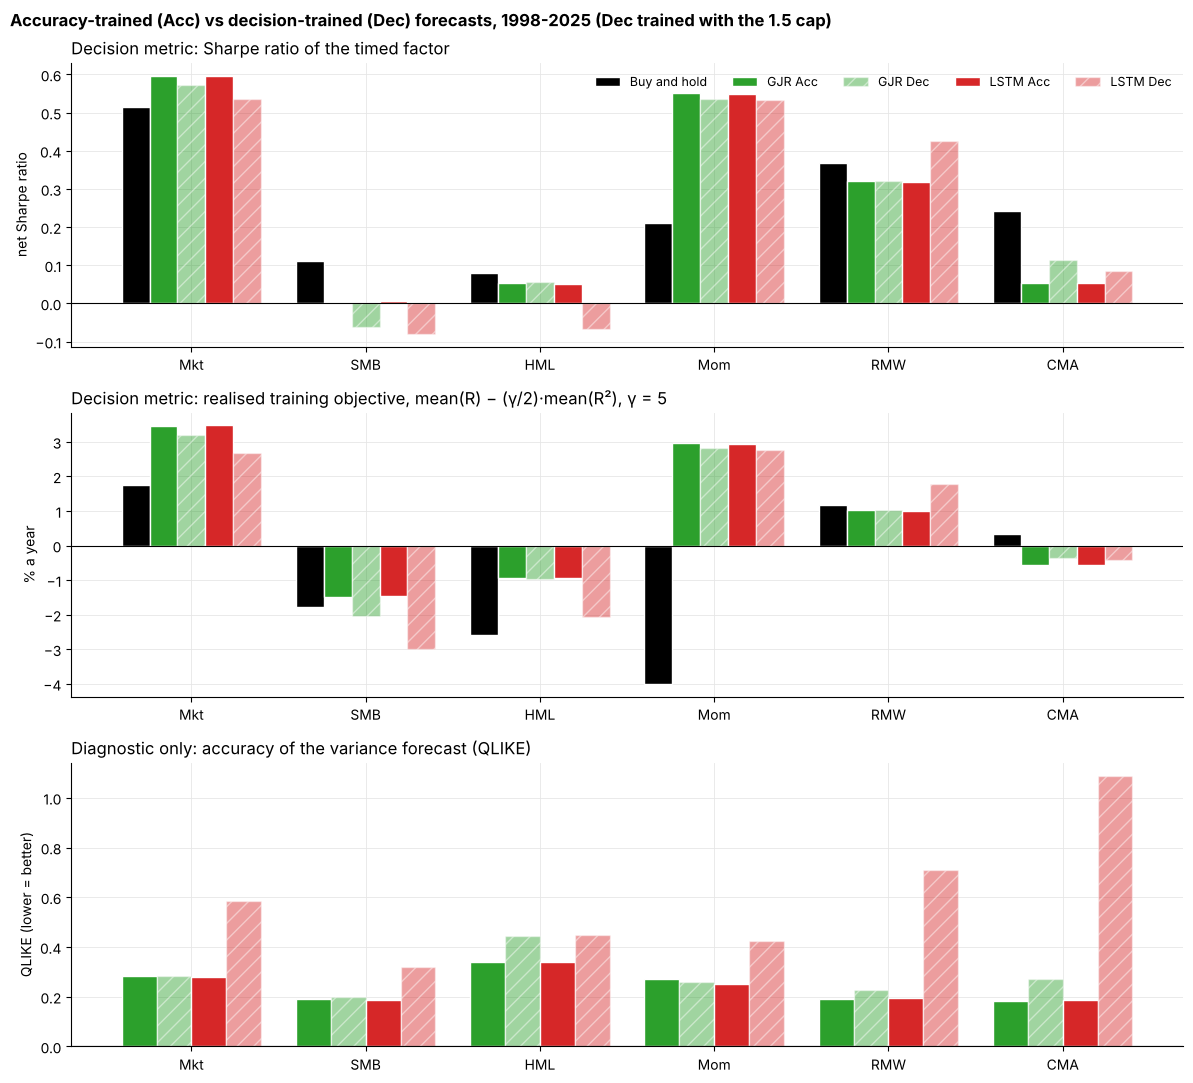

In [25]:
fig, ax = plt.subplots(3, 1, figsize=(12, 11))
x = np.arange(len(DFL_FACTORS))
style = {"Buy and hold": dict(color="black"),
         "GJR Acc": dict(color=COLORS["GJR"]), "GJR Dec": dict(color=COLORS["GJR"], alpha=0.45, hatch="//"),
         "LSTM Acc": dict(color=COLORS["LSTM"]), "LSTM Dec": dict(color=COLORS["LSTM"], alpha=0.45, hatch="//")}
panels = [(dfl_sharpe, list(style), "net Sharpe ratio", "Decision metric: Sharpe ratio of the timed factor"),
          (dfl_util, list(style), "% a year", "Decision metric: realised training objective, mean(R) − (γ/2)·mean(R²), γ = 5"),
          (dfl_qlike, list(style)[1:], "QLIKE (lower = better)", "Diagnostic only: accuracy of the variance forecast (QLIKE)")]
for axis, (tab, keys, ylab, title) in zip(ax, panels):
    wd = 0.8 / len(keys)
    for i, k in enumerate(keys):
        axis.bar(x + (i - (len(keys) - 1) / 2) * wd, tab[k], wd, label=k, edgecolor="white", **style[k])
    axis.axhline(0, color="black", lw=0.8)
    axis.set_ylabel(ylab)
    axis.set_title(title, loc="left")
    axis.set_xticks(x, DFL_FACTORS)
ax[0].legend(frameon=False, ncol=5, fontsize=9)
plt.suptitle("Accuracy-trained (Acc) vs decision-trained (Dec) forecasts, 1998-2025 (Dec trained with the 1.5 cap)",
             x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "fig06_acc_vs_dec.png", dpi=150)
plt.show()

**Inference for Dec minus Acc.** The existing paired calendar-block bootstrap evaluates Sharpe and the exact utility
objective. The existing Romano-Wolf family contains the 12 Sharpe comparisons, two model families across six factors.
Utility p-values remain unadjusted in this implementation; label them accordingly rather than treating Sharpe correction
as a utility correction.


In [26]:
rows = []
for f in DFL_FACTORS:
    for model in ["GJR", "LSTM"]:
        x_, y_ = dfl_nets[(f, f"{model} Dec")].loc[a:b], dfl_nets[(f, f"{model} Acc")].loc[a:b]
        d, lo, hi, p_boot = bootstrap_test(x_, y_)
        du, lou, hiu, pu = bootstrap(paired(x_, y_), lambda X: realised_utility(X[:, 0]) - realised_utility(X[:, 1]))
        rows.append({"factor": f, "model": model, "Sharpe Dec - Acc": d, "Sharpe 95% CI": f"[{lo:+.2f}, {hi:+.2f}]",
                     "Sharpe bootstrap p": p_boot, "Sharpe Ledoit-Wolf p": ledoit_wolf_test(x_, y_)[2],
                     "utility Dec - Acc, %/yr": du, "utility 95% CI": f"[{lou:+.2f}, {hiu:+.2f}]", "utility bootstrap p": pu})
dfl_tests = pd.DataFrame(rows).set_index(["factor", "model"])
rw = romano_wolf({(f, m): (dfl_nets[(f, f"{m} Dec")].loc[a:b], dfl_nets[(f, f"{m} Acc")].loc[a:b])
                  for f in DFL_FACTORS for m in ["GJR", "LSTM"]})
dfl_tests.insert(4, "Sharpe Romano-Wolf p", rw.reindex(dfl_tests.index).to_numpy())
summary_dfl = dfl_tests.groupby(level="model")[["Sharpe Dec - Acc", "utility Dec - Acc, %/yr"]].agg(["mean", lambda s: int((s > 0).sum())])
summary_dfl.columns = [f"{a_} {'average' if b_ == 'mean' else 'factors > 0'}" for a_, b_ in summary_dfl.columns]
display(summary_dfl)
dfl_tests

,Sharpe Dec - Acc average,Sharpe Dec - Acc factors > 0,"utility Dec - Acc, %/yr average","utility Dec - Acc, %/yr factors > 0"
model,,,,
GJR,-0.006,2,-0.138,1
LSTM,-0.024,2,-0.450,2


Sharpe Dec - Acc   Sharpe 95% CI  Sharpe bootstrap p  Sharpe Ledoit-Wolf p  Sharpe Romano-Wolf p  utility Dec - Acc, %/yr  utility 95% CI  \
factor model                                                                                                                                              
Mkt    GJR              -0.023  [-0.04, -0.01]               0.017                 0.016                 0.126                   -0.253  [-0.44, -0.06]   
       LSTM             -0.060  [-0.18, +0.06]               0.303                 0.346                 0.899                   -0.787  [-2.35, +0.77]   
SMB    GJR              -0.064  [-0.12, -0.01]               0.025                 0.011                 0.108                   -0.565  [-1.05, -0.08]   
       LSTM             -0.085  [-0.23, +0.06]               0.226                 0.238                 0.834                   -1.541  [-3.72, +0.63]   
HML    GJR               0.004  [-0.07, +0.08]               0.901                 0.906                 0.992                   -0.024  [-0.51, +0.46]   
       LSTM             -0.119  [-0.28, +0.04]               0.148                 0.158                 0.708                   -1.123  [-2.52, +0.28]   
Mom    GJR              -0.016  [-0.05, +0.01]               0.297                 0.377                 0.899                   -0.168  [-0.50, +0.17]   
       LSTM             -0.016  [-0.10, +0.07]               0.715                 0.727                 0.992                   -0.152  [-1.08, +0.78]   
RMW    GJR              -0.000  [-0.04, +0.04]               0.991                 0.994                 0.992                   -0.008  [-0.25, +0.23]   
       LSTM              0.107  [-0.08, +0.29]               0.248                 0.234                 0.834                    0.779  [-0.52, +2.08]   
CMA    GJR               0.062  [-0.06, +0.19]               0.332                 0.376                 0.899                    0.192  [-0.63, +1.02]   
       LSTM              0.031  [-0.15, +0.21]               0.735                 0.748                 0.992                    0.121  [-0.87, +1.12]   

              utility bootstrap p  
factor model                       
Mkt    GJR                  0.015  
       LSTM                 0.333  
SMB    GJR                  0.028  
       LSTM                 0.147  
HML    GJR                  0.917  
       LSTM                 0.116  
Mom    GJR                  0.313  
       LSTM                 0.746  
RMW    GJR                  0.946  
       LSTM                 0.235  
CMA    GJR                  0.627  
       LSTM                 0.809

**Answering Q3: decision training did not help.**

- **On its own objective (the primary metric),** the decision-trained GARCH-LSTM is worse than the accuracy-trained one
  on average (-0.45% a year) and better on only 2 of 6 factors (RMW +0.78, CMA +0.12); no difference is significant
  (bootstrap p 0.12-0.81).
- **On the Sharpe ratio** it is also worse on average (-0.024) and better on 2 of 6 factors (RMW +0.107, CMA +0.031).
  After the Romano-Wolf adjustment no comparison comes close to significance (p >= 0.71 for the GARCH-LSTM).
- **The GJR control.** With few parameters GJR Dec stays close to Acc on average (Sharpe -0.006), but it is worse on the
  market (-0.023, p 0.017) and SMB (-0.064, p 0.025); neither survives the Romano-Wolf adjustment (p 0.126 and 0.108).
- **The price in accuracy.** The decision-trained forecasts are 1.3 (HML) to 5.8 (CMA) times worse in QLIKE, and still
  1.5 to 4.1 times worse after rescaling each forecast by its best constant, so Dec gives up tracking of volatility, not
  only calibration.
- **The neural part adds little here.** The accuracy-trained GARCH-LSTM and GJR-GARCH have almost the same Sharpe ratio on
  every factor (within 0.005).

A model that does not improve its own objective out of sample has fitted the training years rather than learned a better
rule. We cannot separate overfitting from training instability or changing markets with these tests: the direct check,
the gap between in-sample and out-of-sample objective, is not reported here.


## 7. Conclusion

1. **Timing is a risk tool.** On the US market in 1998-2025 it cut volatility from 15.9% to about 11%, roughly halved the
   worst drawdown (from -50% to between -21% and -29%), lost less than buy and hold in five of six crises and made risk steadier (the
   only gain significant at 5%, unadjusted). The Sharpe gain of +0.08 to +0.10 is not significant and comes from
   1998-2015.
2. **A better forecast does not give a better portfolio.** The accuracy ranking is close to the reverse of the Sharpe
   ranking. Variance is predictable but returns are not, so sharper variance forecasts cut exposure in high-variance months
   that include the best recoveries.
3. **Decision-focused training does not fix it.** Trained on investor utility, the GARCH-LSTM does worse than its
   accuracy-trained version on its own objective on average, improves it on only 2 of 6 factors, and gives up 1.3 to 5.8
   times the forecast accuracy.

**Limitations.** The 1998 start, the cap and the rules compared were settled during exploratory work on the same data, so
the multiple-testing adjustments do not cover that search. The data are today's revised history (a pseudo-out-of-sample
test). The neural monthly forecast extends a one-day forecast with the GJR mean-reversion formula. Each factor is timed as
a single asset, not in a covariance-based portfolio.


## 8. References

- Andersen, T. G., and Bollerslev, T. (1998). Answering the skeptics: Yes, standard volatility models do provide accurate forecasts. *International Economic Review*, 39(4), 885-905.
- Barroso, P., and Santa-Clara, P. (2015). Momentum has its moments. *Journal of Financial Economics*, 116(1), 111-120.
- Black, F. (1976). Studies of stock price volatility changes. *Proceedings of the 1976 Meetings of the American Statistical Association, Business and Economic Statistics Section*, 177-181.
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307-327.
- Bollerslev, T., Tauchen, G., and Zhou, H. (2009). Expected stock returns and variance risk premia. *Review of Financial Studies*, 22(11), 4463-4492.
- Bongaerts, D., Kang, X., and van Dijk, M. (2020). Conditional volatility targeting. *Financial Analysts Journal*, 76(4), 54-71.
- Campbell, J. Y., and Thompson, S. B. (2008). Predicting excess stock returns out of sample: Can anything beat the historical average? *Review of Financial Studies*, 21(4), 1509-1531.
- Clark, T. E., and West, K. D. (2007). Approximately normal tests for equal predictive accuracy in nested models. *Journal of Econometrics*, 138(1), 291-311.
- Cederburg, S., O'Doherty, M. S., Wang, F., and Yan, X. S. (2020). On the performance of volatility-managed portfolios. *Journal of Financial Economics*, 138(1), 95-117.
- Chicago Board Options Exchange (2003). VIX: CBOE Volatility Index. White paper.
- Chicago Board Options Exchange, CBOE Volatility Index: VIX [VIXCLS], retrieved from FRED, Federal Reserve Bank of St. Louis. https://fred.stlouisfed.org/series/VIXCLS
- Elmachtoub, A. N., and Grigas, P. (2022). Smart "predict, then optimize". *Management Science*, 68(1), 9-26.
- French, K. R. Kenneth R. French Data Library. https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
- French, K. R., Schwert, G. W., and Stambaugh, R. F. (1987). Expected stock returns and volatility. *Journal of Financial Economics*, 19(1), 3-29.
- Glosten, L. R., Jagannathan, R., and Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *Journal of Finance*, 48(5), 1779-1801.
- Harvey, C. R., Hoyle, E., Korgaonkar, R., Rattray, S., Sargaison, M., and Van Hemert, O. (2018). The impact of volatility targeting. *Journal of Portfolio Management*, 45(1), 14-33.
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *Annals of Statistics*, 17(3), 1217-1241.
- Ledoit, O., and Wolf, M. (2008). Robust performance hypothesis testing with the Sharpe ratio. *Journal of Empirical Finance*, 15(5), 850-859.
- Moreira, A., and Muir, T. (2017). Volatility-managed portfolios. *Journal of Finance*, 72(4), 1611-1644.
- Moskowitz, T. J., Ooi, Y. H., and Pedersen, L. H. (2012). Time series momentum. *Journal of Financial Economics*, 104(2), 228-250.
- Newey, W. K., and West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703-708.
- Newey, W. K., and West, K. D. (1994). Automatic lag selection in covariance matrix estimation. *Review of Economic Studies*, 61(4), 631-653.
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246-256.
- Politis, D. N., and Romano, J. P. (1992). A circular block-resampling procedure for stationary data. In R. LePage and L. Billard (Eds.), *Exploring the Limits of Bootstrap* (pp. 263-270). Wiley.
- Poon, S.-H., and Granger, C. W. J. (2003). Forecasting volatility in financial markets: A review. *Journal of Economic Literature*, 41(2), 478-539.
- Rapach, D. E., Strauss, J. K., and Zhou, G. (2010). Out-of-sample equity premium prediction: Combination forecasts and links to the real economy. *Review of Financial Studies*, 23(2), 821-862.
- Romano, J. P., and Wolf, M. (2005). Stepwise multiple testing as formalized data snooping. *Econometrica*, 73(4), 1237-1282.
- Shumway, T. (1997). The delisting bias in CRSP data. *Journal of Finance*, 52(1), 327-340.
- Welch, I., and Goyal, A. (2008). A comprehensive look at the empirical performance of equity premium prediction. *Review of Financial Studies*, 21(4), 1455-1508.
- Xu, X. (2024). Improving volatility-managed portfolios in real time. Working paper, ESSCA School of Management. SSRN 4778937. https://ssrn.com/abstract=4778937
- Zhao, P., Zhu, H., Ng, W. S. H., and Lee, D. L. (2024). From GARCH to neural network for volatility forecast. *Proceedings of the AAAI Conference on Artificial Intelligence*, 38(15), 16998-17006.

## Appendix A. Xu's switches and conditional timing

These two rules change *when* the variance rule is used, with information beyond the variance forecast.

**Xu (2024)** starts from the same Moreira-Muir rule and changes three things (his equation 11):

$$g_t = \delta_{t-1}\left(\frac{c^*}{\hat\sigma^2_{t-1}}\right)^{\gamma_{t-1}} f_t$$

1. **Fixed risk target:** $c^*$ is a fixed 12% a year instead of a c matched to past volatility.
2. **Intercept switch $\gamma$:** each month he regresses the last 60 months' returns on last month's variance. If the
   intercept is $\le 0$, $\gamma = 0$ and the exposure is 1 (no timing): if expected returns rise in step with variance,
   cutting exposure in volatile months cuts return as much as risk (Section 5).
3. **Cash switch $\delta$:** if the past 12 months' return is negative, he holds cash.

**Caveat.** The cash switch is a 12-month trend filter, a time-series momentum signal (Moskowitz, Ooi and Pedersen, 2012).
Its gain comes from information about expected returns (the MT side), not from a better variance forecast, so it is not
evidence that better *volatility* timing works. "Xu switches" in this notebook is the two switches on top of our
GARCH(1,1) rule; the last row is his rule as written (his realised variance, 12% target, geometric past-year return), with
our cap and costs.

**Conditional timing** (inspired by Bongaerts, Kang and van Dijk, 2020): our variance rule only in the calmest 20% and
the most volatile 20% of months (by last month's RV, expanding window), exposure 1 otherwise.

In [27]:
def rolling_intercept(r, v, window=60):
    # intercept of the last 60 months' regression of returns on last month's variance
    out = pd.Series(np.nan, index=r.index)
    for i in range(window, len(r)):
        y, x = r.iloc[i - window:i].to_numpy(), v.iloc[i - window:i].to_numpy()
        ok = np.isfinite(x) & np.isfinite(y)
        if ok.sum() >= 48:
            out.iloc[i] = np.polyfit(x[ok], y[ok], 1)[1]
    return out


def xu_pieces(w, e, rv_last, intercept=True, cash=True, geometric=False):
    # Xu's two switches (his eq. 11) on top of any exposure w
    out = w.copy()
    if intercept:          # gamma = 0: the last 60 months say timing does not pay, so hold exposure 1
        out = out.where(rolling_intercept(e, rv_last) > 0, 1.0)
    if cash:               # delta = 0: the past year lost money, so hold cash
        past_year = np.log1p(e).rolling(12).sum() if geometric else e.rolling(12).mean()
        out = out.where(past_year.shift(1) > 0, 0.0)
    return out.where(w.notna()).clip(0, CAP)


W["Xu switches"] = xu_pieces(W[TIMED["GARCH"]], mkt, forecasts["RV"])
nets["Xu switches"] = backtest(W["Xu switches"].loc["1970-01":], mkt)
trades["Xu switches"] = turnover(W["Xu switches"].loc["1970-01":], mkt)


def xu_rv(r_daily):
    # Xu's eq. (2): 22 / (J - 1) times the sum of squared deviations from the month's mean daily return
    v = r_daily.groupby(r_daily.index.to_period("M")).apply(lambda z: 22 / (len(z) - 1) * ((z - z.mean()) ** 2).sum())
    v.index = v.index.astype(str)
    return v.shift(1).reindex(ret.index)


def conditional(w, rv_last):
    q20, q80 = rv_last.expanding(120).quantile(0.2), rv_last.expanding(120).quantile(0.8)
    return w.where((rv_last >= q80) | (rv_last <= q20), 1.0).where(w.notna()).clip(0, CAP)


C_STAR = 0.12 ** 2 / 12    # Xu's fixed target: 12% a year, as a monthly variance
rv_xu = xu_rv(r_mkt.dropna())
XU = {"Timed, GARCH(1,1) (ours)": W[TIMED["GARCH"]],
      "+ intercept switch only": xu_pieces(W[TIMED["GARCH"]], mkt, forecasts["RV"], cash=False),
      "+ cash switch only": xu_pieces(W[TIMED["GARCH"]], mkt, forecasts["RV"], intercept=False),
      "+ both (= Xu switches)": W["Xu switches"],
      "Xu as in his paper": xu_pieces((C_STAR / rv_xu).clip(0, CAP), mkt, rv_xu, geometric=True),
      "Conditional (Bongaerts et al.)": conditional(W[TIMED["GARCH"]], forecasts["RV"])}
xu_nets = {k: backtest(w.loc["1970-01":], mkt) for k, w in XU.items()}

a, b = PERIODS[MAIN]
u = nets["Buy and hold"].loc[a:b]
rows = {}
for k, w in XU.items():
    z = xu_nets[k].loc[a:b]
    mt, vt = mt_vt(w.loc[a:b], mkt.loc[a:b])
    rows[k] = {"Sharpe 1998-2025": sharpe(z), "Sharpe 1998-2015": sharpe(z.loc[:"2015-12"]),
               "Sharpe 2016-2025": sharpe(z.loc["2016-01":]), "Sortino": sortino(z),
               "max DD % (same vol)": 100 * max_drawdown(same_vol_as(z, u), rf.loc[a:b]),
               "MT (gross)": mt, "VT (gross)": vt, "avg exposure": w.loc[a:b].mean(),
               "months in cash %": 100 * (w.loc[a:b] == 0).mean()}
xu_table = pd.DataFrame(rows).T
by_year = lambda mask: {y: int(n) for y, n in mask.groupby(mask.index.str[:4]).sum().items() if n > 0}
print("Xu switches, months in cash by year:", by_year(W["Xu switches"].loc[a:b] == 0))
xu_table

Xu switches, months in cash by year: {'2000': 1, '2001': 12, '2002': 11, '2003': 6, '2008': 11, '2009': 10, '2012': 1, '2015': 1, '2016': 2, '2019': 2, '2020': 1, '2022': 8, '2023': 4}


,Sharpe 1998-2025,Sharpe 1998-2015,Sharpe 2016-2025,Sortino,max DD % (same vol),MT (gross),VT (gross),avg exposure,months in cash %
"Timed, GARCH(1,1) (ours)",0.608,0.460,0.828,0.909,-36.858,0.974,1.269,0.875,0.000
+ intercept switch only,0.589,0.435,0.833,0.875,-47.843,0.976,1.221,0.887,0.000
+ cash switch only,0.657,0.589,0.765,1.005,-28.392,1.096,1.218,0.794,20.833
+ both (= Xu switches),0.679,0.625,0.771,1.045,-28.724,1.141,1.203,0.775,20.833
Xu as in his paper,0.615,0.622,0.615,0.924,-34.368,1.100,1.147,0.679,24.107
Conditional (Bongaerts et al.),0.619,0.449,0.878,0.933,-40.935,1.035,1.199,0.803,0.000


In [28]:
# Xu's switches against buy and hold, by period (bootstrap and Ledoit-Wolf), and the investor measures of Section 3c
rows = []
for p, (a, b) in PERIODS.items():
    z, u = nets["Xu switches"].loc[a:b], nets["Buy and hold"].loc[a:b]
    d, lo, hi, p_boot = bootstrap_test(z, u)
    rows.append({"period": p, "Sharpe gain vs buy and hold": d, "bootstrap 95% CI": f"[{lo:+.2f}, {hi:+.2f}]",
                 "bootstrap p": p_boot, "Ledoit-Wolf p": ledoit_wolf_test(z, u)[2]})
display(pd.DataFrame(rows).set_index("period"))
a, b = PERIODS[MAIN]
z, u = nets["Xu switches"].loc[a:b], nets["Buy and hold"].loc[a:b]
xu_inv = {}
for m, (fn, needs_rf) in MEASURES.items():
    est, lo, hi, p = bootstrap(paired(z, u, rf.loc[a:b]) if needs_rf else paired(z, u), fn)
    sc = 100 if m.startswith("max DD") else 1
    xu_inv[m] = {"gain": sc * est, "95% CI": f"[{sc * lo:+.2f}, {sc * hi:+.2f}]", "p": p}
pd.DataFrame(xu_inv).T

,Sharpe gain vs buy and hold,bootstrap 95% CI,bootstrap p,Ledoit-Wolf p
period,,,,
1998-2025,0.163,"[-0.18, +0.51]",0.350,0.358
1998-2015,0.276,"[-0.14, +0.69]",0.196,0.238
2016-2025,-0.053,"[-0.46, +0.35]",0.796,0.801
2021-2025,0.134,"[-0.33, +0.60]",0.548,0.615


,gain,95% CI,p
Sharpe,0.163,"[-0.18, +0.51]",0.350
Sortino,0.297,"[-0.31, +0.90]",0.339
"max DD at equal vol, pts",21.582,"[-5.13, +48.29]",0.118
"vol of vol at equal vol, pts",-0.596,"[-2.60, +1.41]",0.590
"CER, %/yr",2.468,"[-3.05, +7.99]",0.377


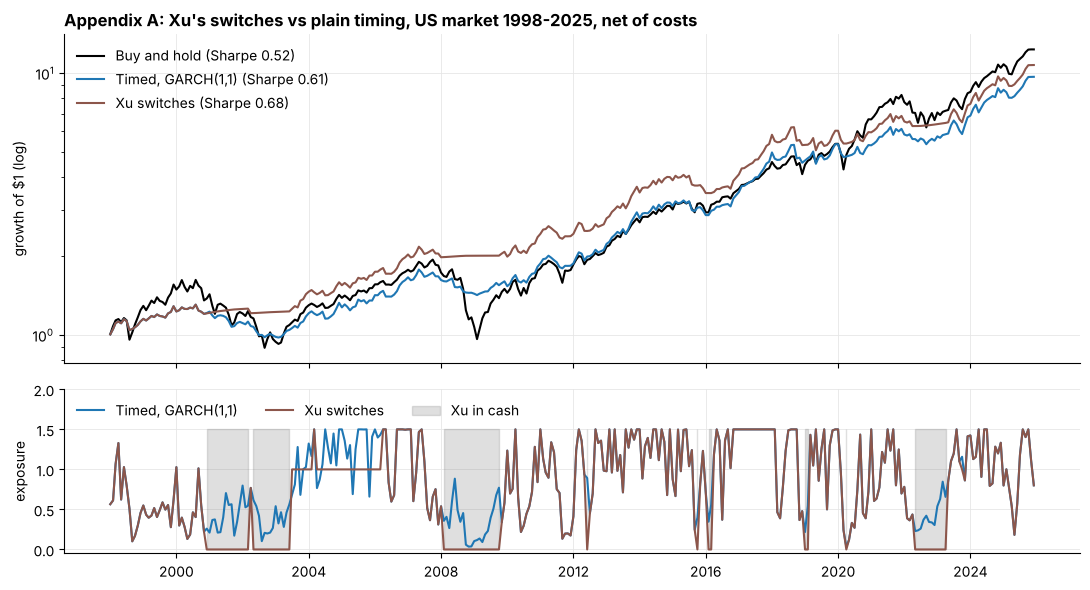

In [29]:
t = as_time(u.index)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for k, col in [("Buy and hold", "black"), (TIMED["GARCH"], COLORS["GARCH"]), ("Xu switches", COLORS["Xu switches"])]:
    z = nets[k].loc[a:b]
    ax[0].plot(t, (1 + z + rf.loc[a:b]).cumprod(), color=col, label=f"{k} (Sharpe {sharpe(z):.2f})")
ax[0].set_yscale("log")
ax[0].set_ylabel("growth of $1 (log)")
ax[0].legend(frameon=False)
w_xu = W["Xu switches"].loc[a:b]
ax[1].plot(t, W[TIMED["GARCH"]].loc[a:b], color=COLORS["GARCH"], label=TIMED["GARCH"])
ax[1].plot(t, w_xu, color=COLORS["Xu switches"], label="Xu switches")
ax[1].fill_between(t, 0, CAP, where=(w_xu == 0).to_numpy(), color="grey", alpha=0.25, label="Xu in cash")
ax[1].set_ylim(-0.05, 2.0)
ax[1].set_ylabel("exposure")
ax[1].legend(loc="upper left", ncol=3, frameon=False)
ax[0].set_title("Appendix A: Xu's switches vs plain timing, US market 1998-2025, net of costs", loc="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "figA_xu.png", dpi=150)
plt.show()

Read the switch and conditional-rule tables as exploratory comparisons. All preserve the original benchmark
implementation. Compare both full-sample and subperiod estimates, exposure and costs; do not choose a rule solely
because it performs best in the explored sample.


## Appendix B. Other benchmarks: equal-weighted CRSP stocks and equal-weighted factors

We do not pick one timed model here. All four timed market portfolios are compared at once with three passive
benchmarks: the market (buy and hold), the equal-weighted course CRSP stocks and the equal-weighted six factors. The CRSP
file covers 2000-2020, so the common window is February 2000 to December 2020.

**Equal volatility.** The portfolios run at very different risk levels (the timed ones at about 11% a year, the market at
16%, the CRSP stocks at about 22% and the factor mix at about 4.5%), so raw drawdowns partly just measure risk. We therefore
also rescale every series, after the fact, to the volatility of each benchmark in turn and recompute its worst drawdown.
Rescaling does not change the Sharpe or Sortino ratio. It is a diagnostic, not a tradable strategy: the scale uses the
whole window, the implied exposure can exceed the 1.5 cap, and costs are not recomputed.

In [30]:
BENCH = {"Buy and hold": nets["Buy and hold"], "EW factors": ew_factors}
if crsp_ex is not None:
    BENCH["EW CRSP stocks"] = crsp_ex


def benchmark_table(a, b, names):
    series = {k: (BENCH[k] if k in BENCH else nets[k]).loc[a:b] for k in names}
    rows = {}
    for k, z in series.items():
        rows[k] = {"Sharpe": sharpe(z), "Sortino": sortino(z), "vol %/yr": 100 * z.std() * 12 ** 0.5,
                   "max DD % (as traded)": 100 * max_drawdown(z, rf.loc[a:b]), "vol of vol %": vol_of_vol(z)}
        for bn in BENCH:
            if bn in series:
                rows[k][f"max DD % at {bn} vol"] = 100 * max_drawdown(same_vol_as(z, series[bn]), rf.loc[a:b])
    return pd.DataFrame(rows).T


if crsp_ex is not None:
    a6, b6 = crsp_ex.index[0], crsp_ex.index[-1]
else:
    a6, b6 = PERIODS[MAIN]
names6 = list(BENCH) + TIMED_MAIN
bench_common = benchmark_table(a6, b6, names6)
print(f"Common window {a6} to {b6}, net of timing costs (benchmarks are passive, no costs)")
bench_common

Common window 2000-02 to 2020-12, net of timing costs (benchmarks are passive, no costs)


,Sharpe,Sortino,vol %/yr,max DD % (as traded),vol of vol %,max DD % at Buy and hold vol,max DD % at EW factors vol,max DD % at EW CRSP stocks vol
Buy and hold,0.435,0.624,15.805,-50.306,6.055,-50.306,-16.307,-63.700
EW factors,0.752,1.206,4.579,-12.211,2.104,-37.369,-12.211,-48.700
EW CRSP stocks,0.497,0.770,22.101,-59.014,8.840,-45.719,-13.894,-59.014
"Timed, RV (last month)",0.558,0.821,10.731,-21.319,3.109,-32.593,-6.306,-44.629
"Timed, GARCH(1,1)",0.560,0.825,10.786,-25.098,2.888,-37.216,-7.567,-49.991
"Timed, GJR-GARCH",0.562,0.829,10.834,-26.323,2.718,-38.579,-8.017,-51.533
"Timed, GARCH-LSTM",0.560,0.822,11.158,-28.659,2.571,-40.412,-8.848,-53.716


The same comparison over the full 1998-2025 sample, without the CRSP stocks:

In [31]:
bench_full = benchmark_table(*PERIODS[MAIN], ["Buy and hold", "EW factors"] + TIMED_MAIN)
bench_full

,Sharpe,Sortino,vol %/yr,max DD % (as traded),vol of vol %,max DD % at Buy and hold vol,max DD % at EW factors vol
Buy and hold,0.516,0.748,15.934,-50.306,5.756,-50.306,-16.137
EW factors,0.714,1.156,4.570,-12.211,2.004,-37.679,-12.211
"Timed, RV (last month)",0.612,0.919,11.003,-21.319,3.152,-32.040,-6.086
"Timed, GARCH(1,1)",0.608,0.909,10.986,-25.098,2.889,-36.858,-7.287
"Timed, GJR-GARCH",0.597,0.891,11.073,-26.802,2.753,-39.753,-7.681
"Timed, GARCH-LSTM",0.597,0.889,11.396,-29.405,2.619,-41.774,-8.504


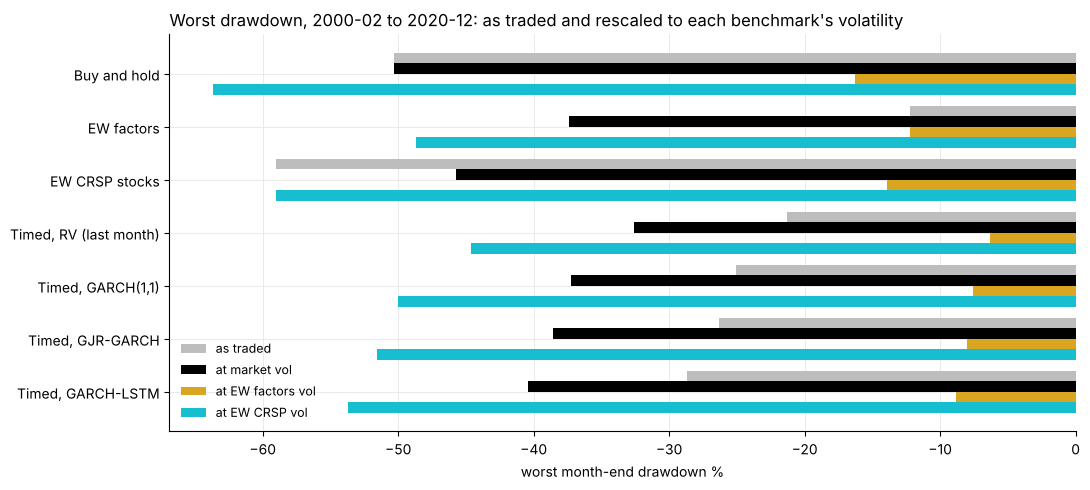

In [32]:
cols = [c for c in bench_common.columns if c.startswith("max DD")]
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(bench_common))
h = 0.8 / len(cols)
shade = {"max DD % (as traded)": "#bdbdbd", "max DD % at Buy and hold vol": "black",
         "max DD % at EW CRSP stocks vol": COLORS["EW CRSP stocks"], "max DD % at EW factors vol": COLORS["EW factors"]}
lab = {"max DD % (as traded)": "as traded", "max DD % at Buy and hold vol": "at market vol",
       "max DD % at EW CRSP stocks vol": "at EW CRSP vol", "max DD % at EW factors vol": "at EW factors vol"}
for i, c in enumerate(cols):
    ax.barh(y + (i - (len(cols) - 1) / 2) * h, bench_common[c], h, color=shade[c], label=lab.get(c, c))
ax.set_yticks(y, bench_common.index)
ax.invert_yaxis()
ax.set_xlabel("worst month-end drawdown %")
ax.set_title(f"Worst drawdown, {a6} to {b6}: as traded and rescaled to each benchmark's volatility", loc="left")
ax.legend(frameon=False, loc="lower left", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / "figB_benchmarks_equal_vol.png", dpi=150)
plt.show()

**Crisis by crisis.** Total return over each episode, as traded and rescaled to the market's volatility (each series over
its own sample: 1998-2025, or 2000-2020 for the CRSP stocks). The CRSP stocks end in 2020, so they have no 2022 bar.

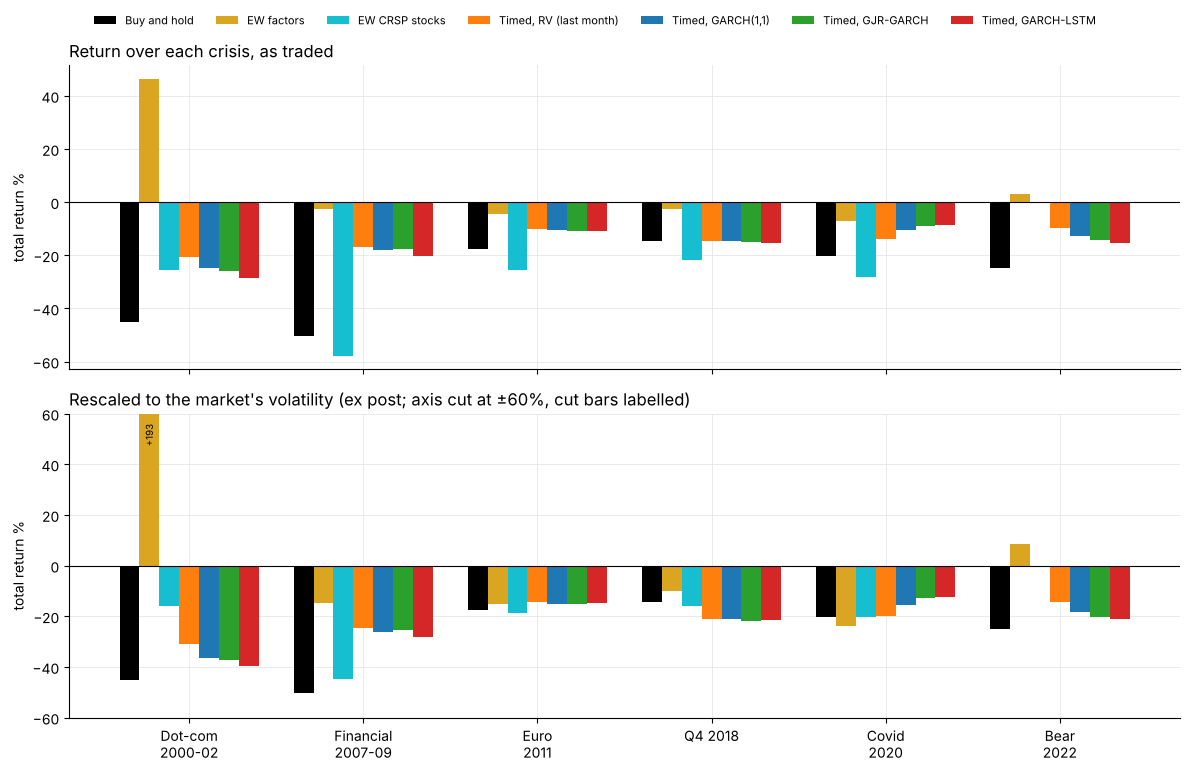

Average exposure in each crisis and in the month after it:


exposure                                                         exposure next month                                     \
                  Timed, RV (last month) Timed, GARCH(1,1) Timed, GJR-GARCH Timed, GARCH-LSTM Timed, RV (last month) Timed, GARCH(1,1) Timed, GJR-GARCH   
Dot-com 2000-02                    0.403             0.451            0.462             0.506                  0.177             0.199            0.180   
Financial 2007-09                  0.317             0.361            0.367             0.415                  0.143             0.137            0.122   
Euro 2011                          0.837             0.829            0.875             0.879                  0.192             0.198            0.173   
Q4 2018                            0.751             0.782            0.791             0.814                  0.201             0.218            0.247   
Covid 2020                         0.786             0.598            0.501             0.496                  0.020             0.034            0.035   
Bear 2022                          0.336             0.388            0.423             0.438                  0.286             0.344            0.276   

                                     
                  Timed, GARCH-LSTM  
Dot-com 2000-02               0.194  
Financial 2007-09             0.160  
Euro 2011                     0.185  
Q4 2018                       0.265  
Covid 2020                    0.054  
Bear 2022                     0.174

In [33]:
a, b = PERIODS[MAIN]
crisis_series = {k: (BENCH[k] if k in BENCH else nets[k]).loc[a:b] for k in names6}
mkt_ref = nets["Buy and hold"].loc[a:b]




crisis = {}
for scaled in (False, True):
    crisis[scaled] = pd.DataFrame({k: {c: episode_return(same_vol_as(z, mkt_ref.loc[z.index]) if scaled else z, s, e)
                                       for c, (s, e) in CRISES.items()} for k, z in crisis_series.items()})
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
x = np.arange(len(CRISES))
wd = 0.8 / len(names6)
for j, scaled in enumerate((False, True)):
    for i, k in enumerate(names6):
        ax[j].bar(x + (i - (len(names6) - 1) / 2) * wd, crisis[scaled][k], wd, color=COLORS[k], label=k)
    ax[j].axhline(0, color="black", lw=0.8)
    ax[j].set_ylabel("total return %")
ax[0].set_title("Return over each crisis, as traded", loc="left")
ax[1].set_title("Rescaled to the market's volatility (ex post; axis cut at ±60%, cut bars labelled)", loc="left")
ax[1].set_xticks(x, list(CRISES))
fig.legend(*ax[0].get_legend_handles_labels(), frameon=False, ncol=7, fontsize=8, loc="upper center",
           bbox_to_anchor=(0.5, 1.03))
ax[1].set_ylim(-60, 60)
for i, k in enumerate(names6):              # label bars that are cut off by the axis limit
    for xi, v in zip(x, crisis[True][k]):
        if np.isfinite(v) and abs(v) > 60:
            ax[1].text(xi + (i - (len(names6) - 1) / 2) * wd, 56 * np.sign(v), f"{v:+.0f}", ha="center",
                       va="top" if v > 0 else "bottom", fontsize=7, rotation=90)
plt.tight_layout()
plt.savefig(FIGURES / "figB_crises_benchmarks.png", dpi=150)
plt.show()

rows = {}
for c, (s, e) in CRISES.items():
    rows[c.replace("\n", " ")] = {**{f"exposure, {k}": W[k].loc[s:e].mean() for k in TIMED_MAIN},
                                  **{f"exposure next month, {k}": W[k].loc[e:].iloc[1] for k in TIMED_MAIN}}
print("Average exposure in each crisis and in the month after it:")
crisis_exposure = pd.DataFrame(rows).T
crisis_exposure.columns = pd.MultiIndex.from_tuples([tuple(c.split(", ", 1)) for c in crisis_exposure.columns])
crisis_exposure


In [34]:
print("Return over each crisis, % (as traded):")
display(crisis[False].rename(index=lambda s: s.replace("\n", " ")))
print("Rescaled to the market's volatility, %:")
crisis[True].rename(index=lambda s: s.replace("\n", " "))

Return over each crisis, % (as traded):


,Buy and hold,EW factors,EW CRSP stocks,"Timed, RV (last month)","Timed, GARCH(1,1)","Timed, GJR-GARCH","Timed, GARCH-LSTM"
Dot-com 2000-02,-44.978,46.254,-25.488,-20.622,-24.901,-25.902,-28.421
Financial 2007-09,-50.306,-2.577,-57.726,-16.889,-17.997,-17.555,-20.282
Euro 2011,-17.649,-4.550,-25.513,-10.163,-10.515,-10.664,-10.787
Q4 2018,-14.527,-2.563,-21.801,-14.551,-14.584,-15.104,-15.528
Covid 2020,-20.198,-6.925,-28.124,-13.859,-10.649,-8.802,-8.716
Bear 2022,-24.829,3.024,NaN,-9.854,-12.639,-14.227,-15.175


Rescaled to the market's volatility, %:


,Buy and hold,EW factors,EW CRSP stocks,"Timed, RV (last month)","Timed, GARCH(1,1)","Timed, GJR-GARCH","Timed, GARCH-LSTM"
Dot-com 2000-02,-44.978,192.967,-15.771,-30.977,-36.438,-37.406,-39.493
Financial 2007-09,-50.306,-14.857,-44.818,-24.503,-26.030,-25.264,-28.079
Euro 2011,-17.649,-15.294,-18.774,-14.467,-14.974,-15.064,-14.827
Q4 2018,-14.527,-10.132,-15.727,-21.031,-21.112,-21.654,-21.618
Covid 2020,-20.198,-23.674,-20.391,-19.900,-15.385,-12.669,-12.194
Bear 2022,-24.829,8.373,NaN,-14.281,-18.199,-20.226,-20.939


**Reading the benchmark comparisons.** Compare all portfolios on their common available window. Equal-volatility
drawdowns are retrospective diagnostics: their scale uses the full comparison period, can exceed the trading cap,
and does not recompute trading costs. Factor and stock benchmarks also have different implementation costs. The CRSP
available-return construction retains its missing-price and absent-delisting-return limitations.


## Appendix C. The six Fama-French factors and factor exposure over time

The same rule, timed on each factor's own GARCH(1,1) forecast, 1998-2025. Each factor is treated as a funded investment,
with 10 bp on changes in the allocation to it; for the long-short factors this leaves out the cost of trading and
shorting the stocks inside them, so it understates the true cost.

In [35]:
a, b = PERIODS[MAIN]
rows, panel_nets = {}, {}
for s in FACTORS:
    v = garch_monthly(s, daily_ret[s]).reindex(ret.index)
    z = backtest(timing_weights(v, ret[s]).loc["1970-01":], ret[s]).loc[a:b]
    panel_nets[s] = z
    us = ret[s].loc[a:b]
    d, se, p_lw = ledoit_wolf_test(z, us)
    rows[s] = {"buy and hold Sharpe": sharpe(us), "timed Sharpe": sharpe(z), "gain": sharpe(z) - sharpe(us),
               "Ledoit-Wolf p": p_lw, "buy and hold max DD %": 100 * max_drawdown(us, rf.loc[a:b]),
               "timed max DD %": 100 * max_drawdown(z, rf.loc[a:b])}
panel = pd.DataFrame(rows).T
panel.insert(4, "Romano-Wolf p", romano_wolf({s: (panel_nets[s], ret[s].loc[a:b]) for s in FACTORS}))
print(f"average gain {panel['gain'].mean():+.2f}, {int((panel['gain'] > 0).sum())} of {len(panel)} gain, "
      f"smaller drawdown in {int((panel['timed max DD %'] > panel['buy and hold max DD %']).sum())} of {len(panel)}")
panel

average gain +0.01, 2 of 6 gain, smaller drawdown in 4 of 6


,buy and hold Sharpe,timed Sharpe,gain,Ledoit-Wolf p,Romano-Wolf p,buy and hold max DD %,timed max DD %
Mkt-RF,0.516,0.608,0.092,0.473,0.844,-50.306,-25.098
SMB,0.111,0.010,-0.101,0.284,0.691,-25.021,-30.609
HML,0.080,0.063,-0.017,0.913,0.912,-52.473,-31.912
RMW,0.367,0.308,-0.060,0.681,0.891,-37.489,-23.223
CMA,0.241,0.049,-0.192,0.152,0.497,-20.960,-25.370
Mom,0.210,0.557,0.347,0.023,0.098,-57.739,-20.606


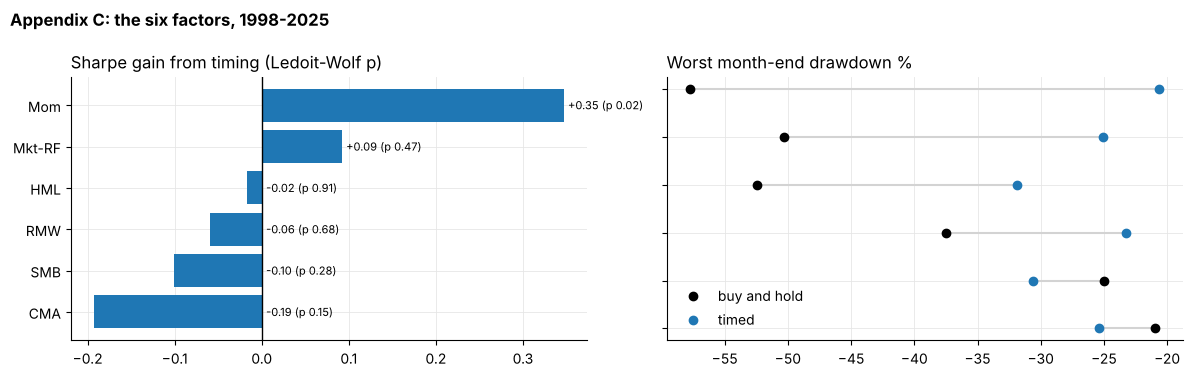

In [36]:
order = panel.sort_values("gain").index
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(order, panel.loc[order, "gain"], color=[COLORS["GARCH"]] * len(order))
for j, s in enumerate(order):
    ax[0].text(max(panel.loc[s, "gain"], 0) + 0.005, j, f"{panel.loc[s, 'gain']:+.2f} (p {panel.loc[s, 'Ledoit-Wolf p']:.2f})",
               va="center", fontsize=8, ha="left")
ax[0].axvline(0, color="black", lw=1)
ax[0].set_title("Sharpe gain from timing (Ledoit-Wolf p)", loc="left")
ax[1].hlines(order, panel.loc[order, "buy and hold max DD %"], panel.loc[order, "timed max DD %"], color="lightgrey")
ax[1].plot(panel.loc[order, "buy and hold max DD %"], order, "o", color="black", label="buy and hold")
ax[1].plot(panel.loc[order, "timed max DD %"], order, "o", color=COLORS["GARCH"], label="timed")
ax[1].set_yticklabels([])
ax[1].set_title("Worst month-end drawdown %", loc="left")
ax[1].legend(frameon=False)
plt.suptitle("Appendix C: the six factors, 1998-2025", x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "figC_factors.png", dpi=150)
plt.show()

**Factor exposure over time.** Plain GARCH keeps its original estimator. GJR Acc and LSTM Acc/Dec use the same
completed forecast files and exported exposures as the main and decision-focused comparisons. The LSTM ensemble is
formed before allocation. Factor names are mapped once to the common core series.


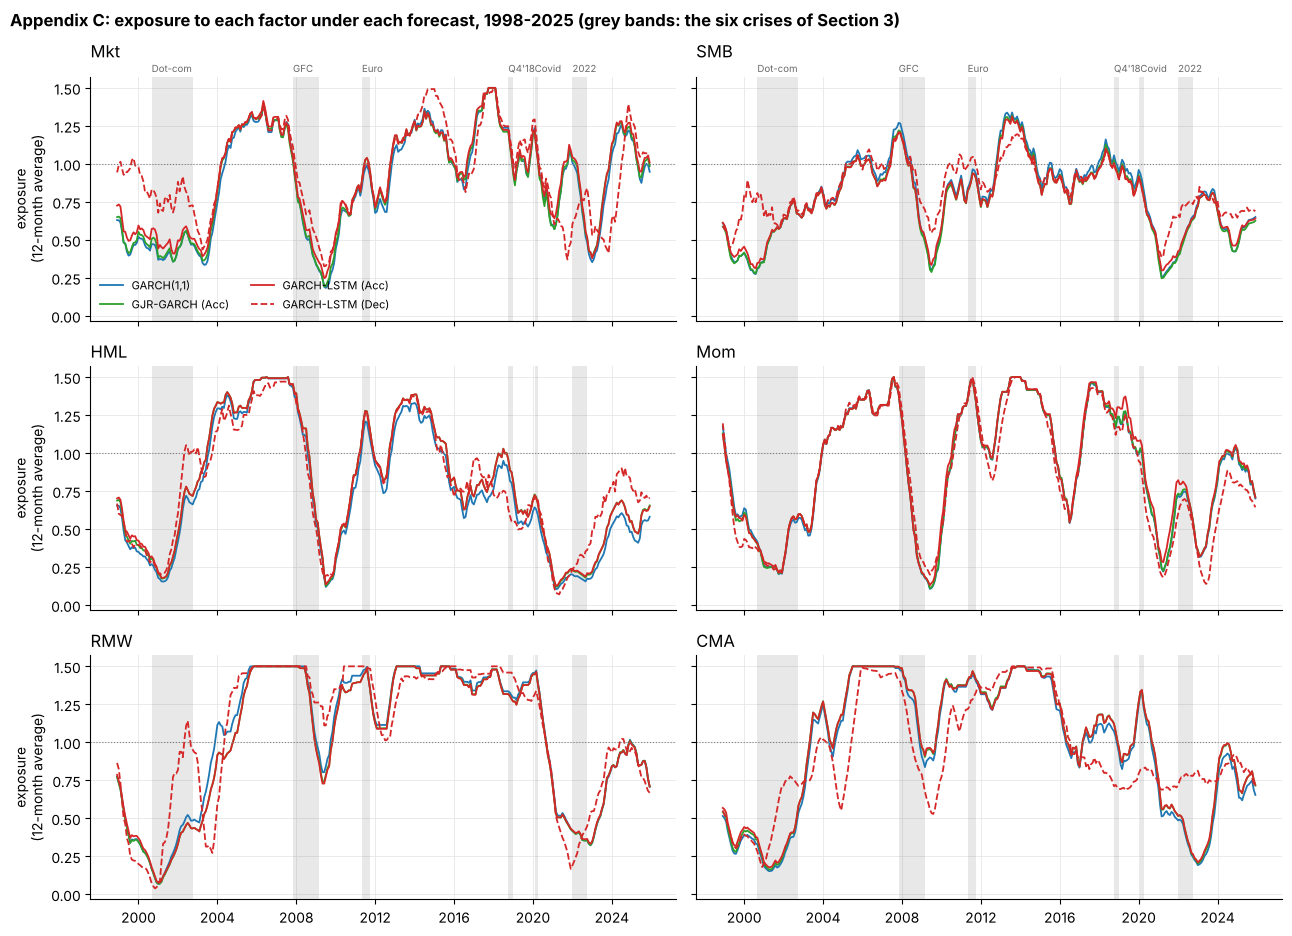

Average exposure, 1998-2025:


,"GARCH(1,1)",GJR-GARCH (Acc),GARCH-LSTM (Acc),GARCH-LSTM (Dec)
Mkt,0.875,0.893,0.919,0.959
SMB,0.781,0.758,0.765,0.832
HML,0.751,0.799,0.802,0.805
Mom,0.912,0.915,0.929,0.875
RMW,1.041,1.016,1.017,1.068
CMA,0.956,0.984,0.987,0.931


In [37]:
FIRST_TWO_FACTORS = tuple(DFL_FACTORS)[:2]

def shade_crises(ax_, label=False, y=1.55):
    # grey bands for the six crisis episodes of Section 3 (month-end dates, so a band starts at its first month)
    for name, (s, e) in CRISES.items():
        t0, t1 = pd.Period(s, "M").to_timestamp(), pd.Period(e, "M").to_timestamp(how="end")
        ax_.axvspan(t0, t1, color="grey", alpha=0.18, lw=0)
        if label:   # short names just above the plot area
            short_name = {"Dot-com": "Dot-com", "Financial": "GFC", "Euro": "Euro", "Q4 2018": "Q4'18", "Covid": "Covid",
                          "Bear": "2022"}[name.split("\n")[0]]
            ax_.text(t0, 1.01, short_name, fontsize=7, color="dimgrey", va="bottom", ha="left",
                     transform=ax_.get_xaxis_transform())
a, b = PERIODS[MAIN]
fig, axes = plt.subplots(3, 2, figsize=(13, 9.5), sharex=True, sharey=True)
expo_avg = {}
for ax_, f in zip(axes.ravel(), DFL_FACTORS):
    s, g = DFL_FACTORS[f], lstm_files[f]
    series = {"GARCH(1,1)": (timing_weights(garch_monthly(s, daily_ret[s]).reindex(ret.index), ret[s]), COLORS["GARCH"], "-"),
              "GJR-GARCH (Acc)": (g["W_gjr_A"], COLORS["GJR"], "-"),
              "GARCH-LSTM (Acc)": (g["W_zhao_A_ensemble"], COLORS["LSTM"], "-"),
              "GARCH-LSTM (Dec)": (g["W_zhao_B_ensemble"], COLORS["LSTM"], "--")}
    expo_avg[f] = {}
    for name, (w, col, ls) in series.items():
        w = w.loc[a:b]
        expo_avg[f][name] = w.mean()
        ax_.plot(as_time(w.index), w.rolling(12).mean(), color=col, ls=ls, lw=1.3, label=name)
    ax_.axhline(1, color="grey", ls=":", lw=0.8)
    shade_crises(ax_, label=f in FIRST_TWO_FACTORS)
    ax_.set_title(f, loc="left", pad=14 if f in FIRST_TWO_FACTORS else 6)
axes[0, 0].legend(frameon=False, fontsize=8, ncol=2, loc="lower left")
for r_ in range(3):
    axes[r_, 0].set_ylabel("exposure\n(12-month average)")
plt.suptitle("Appendix C: exposure to each factor under each forecast, 1998-2025 (grey bands: the six crises of Section 3)",
             x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "figC_factor_exposures.png", dpi=150)
plt.show()
print("Average exposure, 1998-2025:")
pd.DataFrame(expo_avg).T


**Reading the factor results.** Timing each factor on its own GARCH(1,1) forecast helps only the market (+0.09) and
momentum (+0.35, Ledoit-Wolf p 0.023, Romano-Wolf 0.098); it lowers the Sharpe ratio of SMB, HML, RMW and CMA (by up to
0.19), for an average gain of +0.01. Drawdowns are smaller for 4 of 6 factors. In the exposure plot the decision-trained
GARCH-LSTM holds more of the market, SMB and RMW and less of momentum and CMA than the accuracy-trained one; larger
average exposure is not itself timing skill. These remain single-asset experiments, not covariance-based allocation.


## Appendix D. Building the rule one piece at a time, and Moreira and Muir's choice of c

**Rule build-up** (GARCH(1,1) forecast). We start from buy and hold and add one piece at a time. Drawdowns and vol of vol
are measured after rescaling to the volatility of buy and hold.

In [38]:
a, b = PERIODS[MAIN]
u = nets["Buy and hold"].loc[a:b]
v_garch = forecasts["GARCH"]
steps = {
    "1. Buy and hold": (W["Buy and hold"], 0.0),
    "2. Scale by 1/σ (vol target), no cap, no costs": (timing_weights(np.sqrt(v_garch), mkt, cap=None), 0.0),
    "3. Scale by 1/σ² instead (Moreira-Muir)": (timing_weights(v_garch, mkt, cap=None), 0.0),
    "4. + cap exposure at 1.5": (timing_weights(v_garch, mkt), 0.0),
    "5. + 10 bp trading costs (our rule)": (timing_weights(v_garch, mkt), COST),
    # c estimated on 1970-1997, so this rule starts in January 1998 (first position entered free)
    "6. c set once (1970-1997) instead of every January": (timing_weights(v_garch, mkt, frozen_window=("1970-01", "1997-12")).loc["1998-01":], COST),
}
rows = {}
for name, (w, cost) in steps.items():
    z = backtest(w.loc["1970-01":], mkt, cost=cost).loc[a:b]
    mt, vt = mt_vt(w.loc[a:b], mkt.loc[a:b])
    rows[name] = {"Sharpe": sharpe(z), "Sortino": sortino(z), "max DD % (same vol)": 100 * max_drawdown(same_vol_as(z, u), rf.loc[a:b]),
                  "vol of vol %": vol_of_vol(same_vol_as(z, u)), "traded per year": 12 * turnover(w.loc["1970-01":], mkt).loc[a:b].mean(),
                  "MT (gross)": mt, "VT (gross)": vt}
ablation_rule = pd.DataFrame(rows).T
ablation_rule

,Sharpe,Sortino,max DD % (same vol),vol of vol %,traded per year,MT (gross),VT (gross)
1. Buy and hold,0.516,0.748,-50.306,5.756,0.000,1.000,1.000
"2. Scale by 1/σ (vol target), no cap, no costs",0.614,0.908,-42.813,3.505,2.363,0.986,1.208
3. Scale by 1/σ² instead (Moreira-Muir),0.608,0.897,-34.073,5.174,3.894,0.953,1.237
4. + cap exposure at 1.5,0.637,0.960,-36.365,4.196,3.279,0.974,1.269
5. + 10 bp trading costs (our rule),0.608,0.909,-36.858,4.191,3.279,0.974,1.269
6. c set once (1970-1997) instead of every January,0.574,0.843,-39.344,4.173,3.235,0.932,1.264


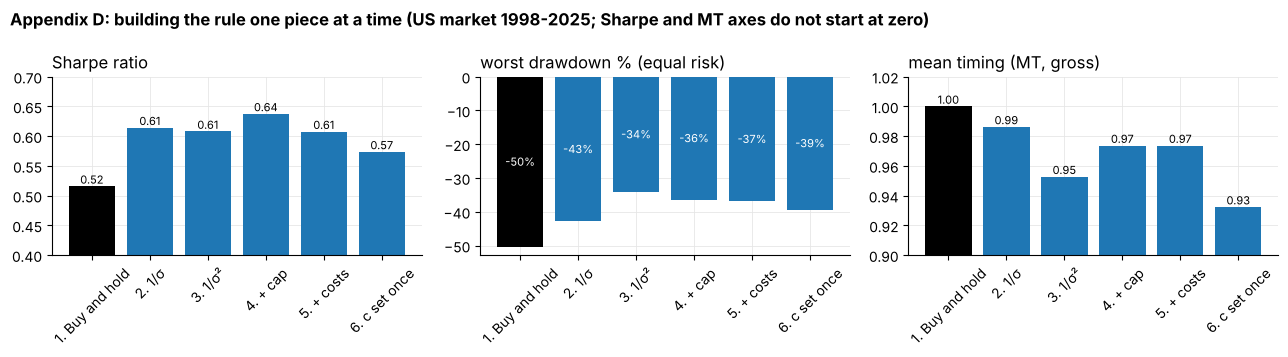

In [39]:
short = ["1. Buy and hold", "2. 1/σ", "3. 1/σ²", "4. + cap", "5. + costs", "6. c set once"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for i, col in enumerate(["Sharpe", "max DD % (same vol)", "MT (gross)"]):
    ax[i].bar(short, ablation_rule[col], color=["black"] + [COLORS["GARCH"]] * 5)
    for j, v in enumerate(ablation_rule[col]):
        if i == 1:
            ax[i].text(j, v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white")
        else:
            ax[i].text(j, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax[i].set_title({"Sharpe": "Sharpe ratio", "max DD % (same vol)": "worst drawdown % (equal risk)",
                     "MT (gross)": "mean timing (MT, gross)"}[col], loc="left")
    ax[i].tick_params(axis="x", rotation=45)
ax[0].set_ylim(0.4, 0.7)
ax[2].set_ylim(0.9, 1.02)
plt.suptitle("Appendix D: building the rule one piece at a time (US market 1998-2025; Sharpe and MT axes do not start at zero)",
             x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "figD_rule_buildup.png", dpi=150)
plt.show()

**Fixed full-sample c diagnostic.** Compare each primary policy with a c fitted once on its evaluation-period forecast
and return series. This uses hindsight and is not executable in advance. For GJR/LSTM, the comparison also changes the
calibration history from current-model re-filtered history to the evaluation forecast series; it is not an isolated
estimate of the effect of annual resetting alone.


In [40]:
a, b = PERIODS[MAIN]
rows = {}
for k in accuracy.sort_values(ascending=False).index:
    w_mm = timing_weights(forecasts[k], mkt, frozen_window=(a, b))
    rows[LABEL[k]] = {"Sharpe, primary policy (past only)": sharpe(nets[TIMED[k]].loc[a:b]),
                      "Sharpe, fixed evaluation-sample c (ex post)": sharpe(backtest(w_mm.loc["1970-01":], mkt).loc[a:b])}
mm_c = pd.DataFrame(rows).T
mm_c["difference"] = mm_c.iloc[:, 1] - mm_c.iloc[:, 0]
mm_c


,"Sharpe, primary policy (past only)","Sharpe, fixed evaluation-sample c (ex post)",difference
RV (last month),0.612,0.580,-0.032
"GARCH(1,1)",0.608,0.579,-0.029
GJR-GARCH,0.597,0.572,-0.024
GARCH-LSTM,0.597,0.578,-0.019
VIX²,0.545,0.517,-0.028


Read the GARCH rule-build-up table to see how scaling, the cap, costs and a frozen pre-test c change the original
GARCH benchmark. Read the full-sample-c table as a retrospective diagnostic with the caveat above. These calculations
do not retrain or replace the completed GJR/LSTM portfolios.


## Appendix E. Further checks

**E1. Forecast accuracy (QLIKE) by sub-period.**

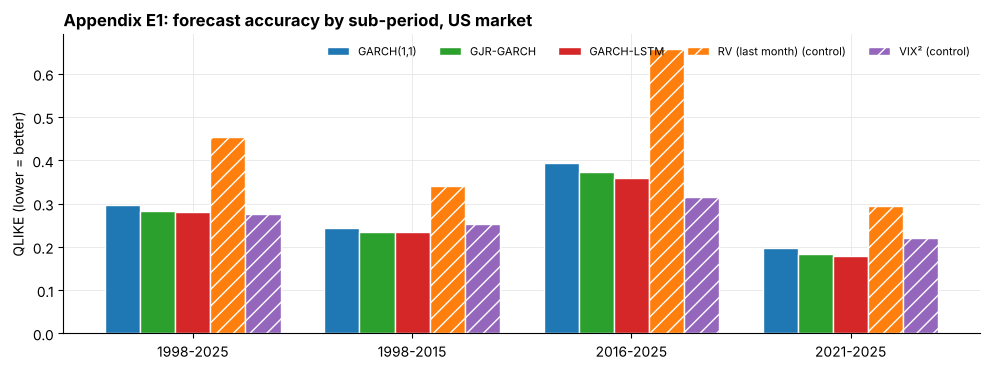

,1998-2025,1998-2015,2016-2025,2021-2025
"GARCH(1,1)",0.297,0.243,0.394,0.198
GJR-GARCH,0.284,0.235,0.372,0.183
GARCH-LSTM,0.280,0.235,0.360,0.178
RV (last month),0.454,0.341,0.658,0.295
VIX²,0.275,0.253,0.314,0.222


In [41]:
qlike_periods = pd.DataFrame({p: {LABEL[k]: qlike(forecasts[k].loc[a:b], rv_eval["Mkt-RF"].loc[a:b]) for k in FORECASTS}
                              for p, (a, b) in PERIODS.items()})
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(PERIODS))
wd = 0.8 / len(FORECASTS)
for i, k in enumerate(FORECASTS):
    ax.bar(x + (i - (len(FORECASTS) - 1) / 2) * wd, qlike_periods.loc[LABEL[k]], wd, color=COLORS[k],
           label=LABEL[k] + (" (control)" if k in CONTROLS else ""), hatch="//" if k in CONTROLS else None, edgecolor="white")
ax.set_xticks(x, list(PERIODS))
ax.set_ylabel("QLIKE (lower = better)")
ax.set_title("Appendix E1: forecast accuracy by sub-period, US market", loc="left", weight="bold")
ax.legend(frameon=False, ncol=5, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "figE_qlike_periods.png", dpi=150)
plt.show()
qlike_periods


**Reading E1.** The ranking depends on the period: GJR and the GARCH-LSTM are the most accurate in 1998-2015 (0.235)
and the GARCH-LSTM in 2021-2025 (0.178), while VIX² is best in 2016-2025 (0.314), which gives it the full-sample lead.
RV is the least accurate in every period. Small differences should be read with the number of months and the dependence
in forecast errors in mind.


**E2. Returns sorted by forecast volatility.** The months of 1998-2025 in five equal groups by the real-time GARCH(1,1)
forecast (group breakpoints from the whole sample, so this is a description, not a trading rule): next month's realised
volatility, average excess return and return per unit of variance (Moreira and Muir, 2017, Figure 1).

In [42]:
a, b = PERIODS[MAIN]
true_var, next_ret = rv_eval["Mkt-RF"].loc[a:b], mkt.loc[a:b]
def by_forecast_group(v, n=5):
    g = pd.qcut(v, n, labels=[f"{i + 1}" for i in range(n)])
    d = pd.DataFrame({"g": g, "ret": next_ret, "rv": true_var, "v": v})
    out = d.groupby("g", observed=True).agg(months=("ret", "size"), forecast_vol=("v", lambda x: 100 * np.sqrt(12 * x.mean())),
                                            realised_vol=("rv", lambda x: 100 * np.sqrt(12 * x.mean())),
                                            ret=("ret", "mean"), sd=("ret", "std"), var=("rv", "mean"))
    out["excess return %/yr"] = 1200 * out["ret"]
    out["95% interval +/-"] = 1200 * 1.96 * out["sd"] / np.sqrt(out["months"])       # treats months as independent
    out["return per unit variance"] = out["ret"] / out["var"]
    return out.rename(columns={"forecast_vol": "forecast vol %/yr", "realised_vol": "realised vol next month %/yr"}).drop(columns=["ret", "sd", "var"])


groups = by_forecast_group(forecasts["GARCH"].loc[a:b])
print("Months sorted into five groups by the GARCH(1,1) forecast (1 = calmest), 1998-2025:")
display(groups)
print("Return per unit variance by group, for every forecast:")
pd.DataFrame({LABEL[k]: by_forecast_group(forecasts[k].loc[a:b])["return per unit variance"] for k in FORECASTS}).T


Months sorted into five groups by the GARCH(1,1) forecast (1 = calmest), 1998-2025:


,months,forecast vol %/yr,realised vol next month %/yr,excess return %/yr,95% interval +/-,return per unit variance
g,,,,,,
1,68,9.962,11.467,8.269,7.280,6.289
2,67,12.132,13.380,5.756,8.270,3.216
3,67,14.947,14.131,16.343,11.795,8.185
4,67,18.357,22.074,-3.985,15.505,-0.818
5,67,31.670,30.376,14.703,19.207,1.593


Return per unit variance by group, for every forecast:


g,1,2,3,4,5
"GARCH(1,1)",6.289,3.216,8.185,-0.818,1.593
GJR-GARCH,3.444,4.595,7.168,0.019,1.549
GARCH-LSTM,4.225,4.046,6.766,0.290,1.426
RV (last month),5.059,4.478,1.419,3.389,1.001
VIX²,3.197,7.087,1.547,0.994,1.886


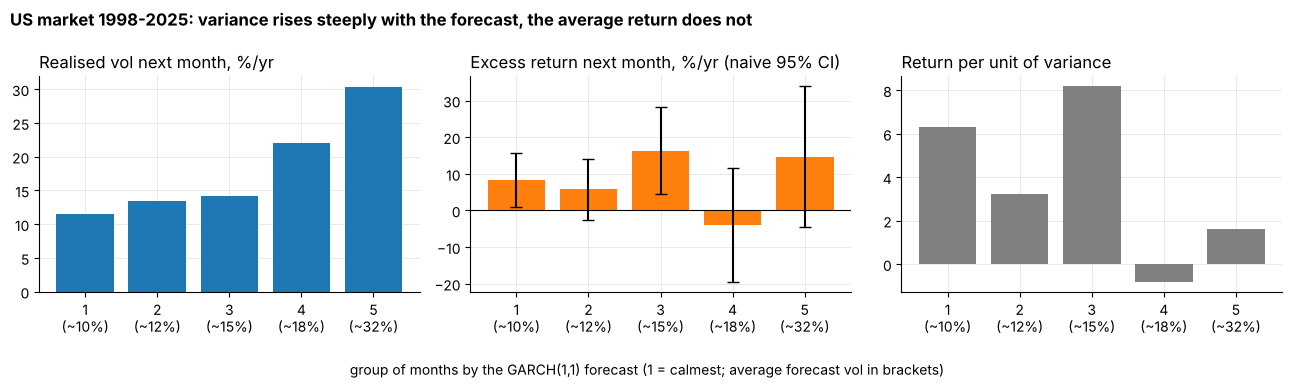

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
x = np.arange(len(groups))
lab = [f"{i}\n(~{v:.0f}%)" for i, v in zip(groups.index, groups["forecast vol %/yr"])]
ax[0].bar(x, groups["realised vol next month %/yr"], color=COLORS["GARCH"])
ax[0].set_title("Realised vol next month, %/yr", loc="left")
ax[1].bar(x, groups["excess return %/yr"], yerr=groups["95% interval +/-"], color="tab:orange", capsize=4)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_title("Excess return next month, %/yr (naive 95% CI)", loc="left")
ax[2].bar(x, groups["return per unit variance"], color="grey")
ax[2].set_title("Return per unit of variance", loc="left")
for a_ in ax:
    a_.set_xticks(x, lab)
fig.supxlabel("group of months by the GARCH(1,1) forecast (1 = calmest; average forecast vol in brackets)", fontsize=10)
plt.suptitle("US market 1998-2025: variance rises steeply with the forecast, the average return does not",
             x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "figE_vol_groups.png", dpi=150)
plt.show()

The groups describe forecast variance, subsequent RV and subsequent excess returns. Their breakpoints use the whole
evaluation sample, so they are descriptive rather than trading signals. Return intervals are naive and treat months as
independent. Interpret noisy differences as possible mechanisms, not reliable return predictions or causal explanations.


**E3. Market exposure of each timed model over time** (grey bands: the six crises of Section 3).

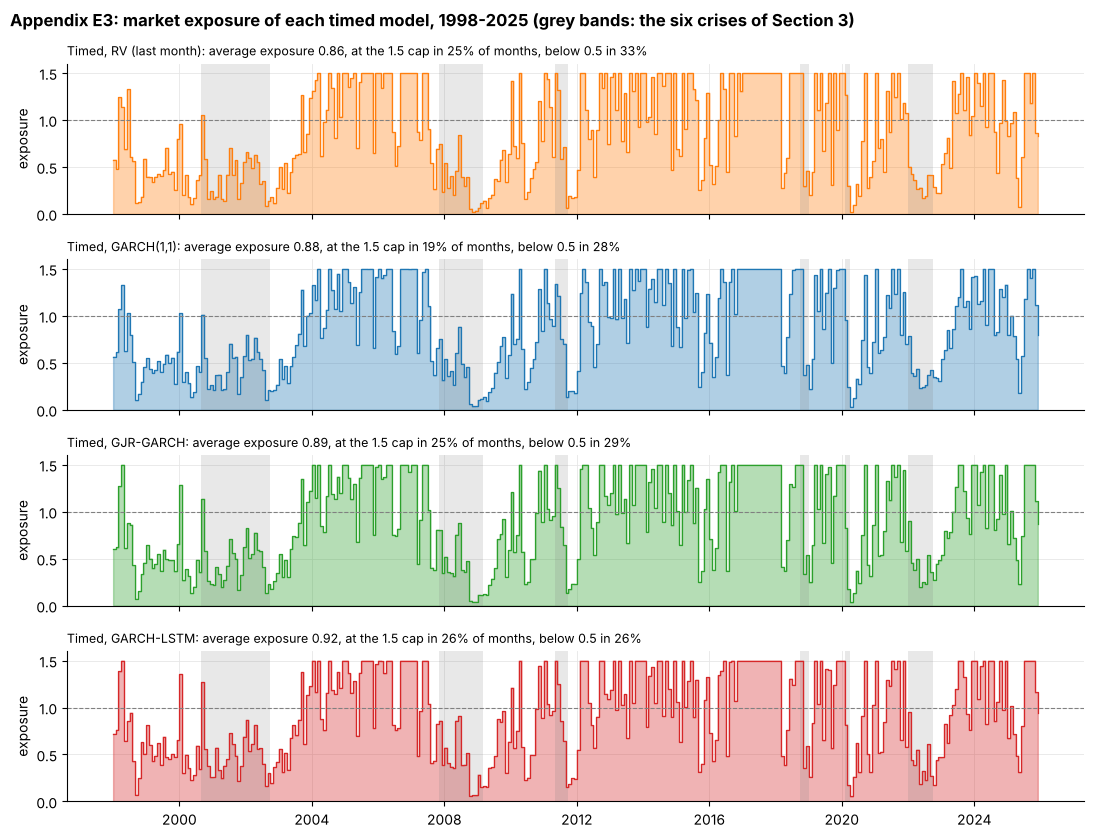

Average exposure by year:


month,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
"Timed, RV (last month)",0.636,0.455,0.403,0.352,0.365,0.655,1.219,1.337,1.288,0.920,...,1.022,1.500,1.047,1.026,0.600,1.094,0.313,1.015,1.181,0.942
"Timed, GARCH(1,1)",0.630,0.480,0.436,0.391,0.434,0.677,1.211,1.276,1.286,0.936,...,1.076,1.500,1.058,1.095,0.600,1.067,0.373,0.989,1.213,0.948
"Timed, GJR-GARCH",0.649,0.499,0.470,0.395,0.448,0.743,1.236,1.298,1.289,0.926,...,1.110,1.500,1.034,1.091,0.594,1.073,0.417,1.043,1.244,0.984
"Timed, GARCH-LSTM",0.725,0.549,0.535,0.446,0.484,0.761,1.239,1.301,1.309,0.950,...,1.132,1.500,1.052,1.117,0.666,1.088,0.419,1.048,1.270,1.009


In [44]:
a, b = PERIODS[MAIN]
t = as_time(ret.loc[a:b].index)
fig, ax = plt.subplots(len(TIMED_MAIN), 1, figsize=(11, 8.5), sharex=True, sharey=True)
for i, k in enumerate(TIMED_MAIN):
    w = W[k].loc[a:b]
    ax[i].fill_between(t, 0, w, color=COLORS[k], alpha=0.35, step="post")
    ax[i].step(t, w, color=COLORS[k], lw=0.9, where="post")
    ax[i].axhline(1, color="grey", ls="--", lw=0.8)
    for name, (s, e) in CRISES.items():
        ax[i].axvspan(pd.Period(s, "M").to_timestamp(), pd.Period(e, "M").to_timestamp(how="end"), color="grey", alpha=0.18, lw=0)
    ax[i].set_title(f"{k}: average exposure {w.mean():.2f}, at the 1.5 cap in {100 * (w >= CAP - 1e-9).mean():.0f}% of months, "
                    f"below 0.5 in {100 * (w < 0.5).mean():.0f}%", loc="left", fontsize=9)
    ax[i].set_ylabel("exposure")
ax[0].set_ylim(0, 1.6)
plt.suptitle("Appendix E3: market exposure of each timed model, 1998-2025 (grey bands: the six crises of Section 3)", x=0.01, ha="left", weight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "figE_exposures.png", dpi=150)
plt.show()

annual = pd.DataFrame({k: W[k].loc[a:b].groupby(W[k].loc[a:b].index.str[:4]).mean() for k in TIMED_MAIN})
print("Average exposure by year:")
annual.T

**E4. Ledoit-Wolf bandwidth check.** The Ledoit-Wolf test uses a rule-of-thumb number of HAC lags (5 for 336 months). Here
the main comparisons are re-tested with 0 to 12 lags.

In [45]:
checks = {f"{k} vs buy and hold": (nets[k], nets["Buy and hold"]) for k in SIG_RULES + ["Xu switches"]}
checks["Momentum timed vs buy and hold (Appendix C)"] = (panel_nets["Mom"], ret["Mom"])
a, b = PERIODS[MAIN]
rows = {}
for name, (x, y) in checks.items():
    rows[name] = {f"{L} lags": ledoit_wolf_test(x.loc[a:b], y.loc[a:b], lags=L)[2] for L in [0, 3, 6, 12]}
    rows[name]["rule of thumb (5)"] = ledoit_wolf_test(x.loc[a:b], y.loc[a:b])[2]
pd.DataFrame(rows).T

,0 lags,3 lags,6 lags,12 lags,rule of thumb (5)
"Timed, RV (last month) vs buy and hold",0.485,0.489,0.486,0.481,0.491
"Timed, GARCH(1,1) vs buy and hold",0.476,0.476,0.464,0.440,0.473
"Timed, GJR-GARCH vs buy and hold",0.537,0.537,0.524,0.503,0.532
"Timed, GARCH-LSTM vs buy and hold",0.516,0.506,0.487,0.467,0.497
Xu switches vs buy and hold,0.322,0.338,0.358,0.348,0.358
Momentum timed vs buy and hold (Appendix C),0.022,0.022,0.022,0.017,0.023
